# QC, clustering & initial analysis of single-cell RNA-seq data

This notebook imports the cellranger outputs (barcodes.tsv.gz, features.tsv.gz, matrix.mtx.gz) and creates a scanpy object. The notebook performs quality control, filtering, normalization, clustering and cluster annotation.

# Imports

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import decoupler as dc
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Patch
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu
import anndata as ad
from adjustText import adjust_text

In [2]:
sc.settings.verbosity = 3            
sc.logging.print_header()
sc.settings.set_figure_params(dpi=80, facecolor='white')

# If notebook is saved in the same folder as the folders containing the barcodes.tsv.gz, features.tsv.gz, matrix.mtx.gz files, this will work, otherwise set the directory accordingly
adata_hfd1 = sc.read_10x_mtx('HFD1') 
adata_hfd2 = sc.read_10x_mtx('HFD2')
adata_lfd = sc.read_10x_mtx('LFD') 


scanpy==1.10.4 anndata==0.11.1 umap==0.5.7 numpy==2.0.2 scipy==1.14.1 pandas==2.2.3 scikit-learn==1.6.0 statsmodels==0.14.4 igraph==0.11.8 pynndescent==0.5.13
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.


In [3]:
# specify what the results file should be saved to
results_file = 'cd4_sorted_260326.h5ad'

In [4]:
# HFD1 and HFD2 can be pooled - both will get the label HFD 
adata_hfd1.obs['sample'] = 'HFD'
adata_hfd2.obs['sample'] = 'HFD'
adata_lfd.obs['sample'] = 'LFD'

# merge samples
# adata = adata_hfd1.concatenate(adata_lfd, adata_hfd2)
adata = ad.concat([adata_hfd1, adata_lfd, adata_hfd2], merge='same', index_unique='-')


# QC and data preparation

Filter out low quality cells & genes, annotate mitochondrial genes

In [5]:
# filter out genes that are expressed in fewer than 3 cells and cells that have fewer than 200 transcripts
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

# annotate mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("mt-")

filtered out 10 cells that have less than 200 genes expressed
filtered out 31150 genes that are detected in less than 3 cells


Calculate QC metrics

In [6]:
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt"], percent_top=None, log1p=True, inplace=True
)

Show QC metrics

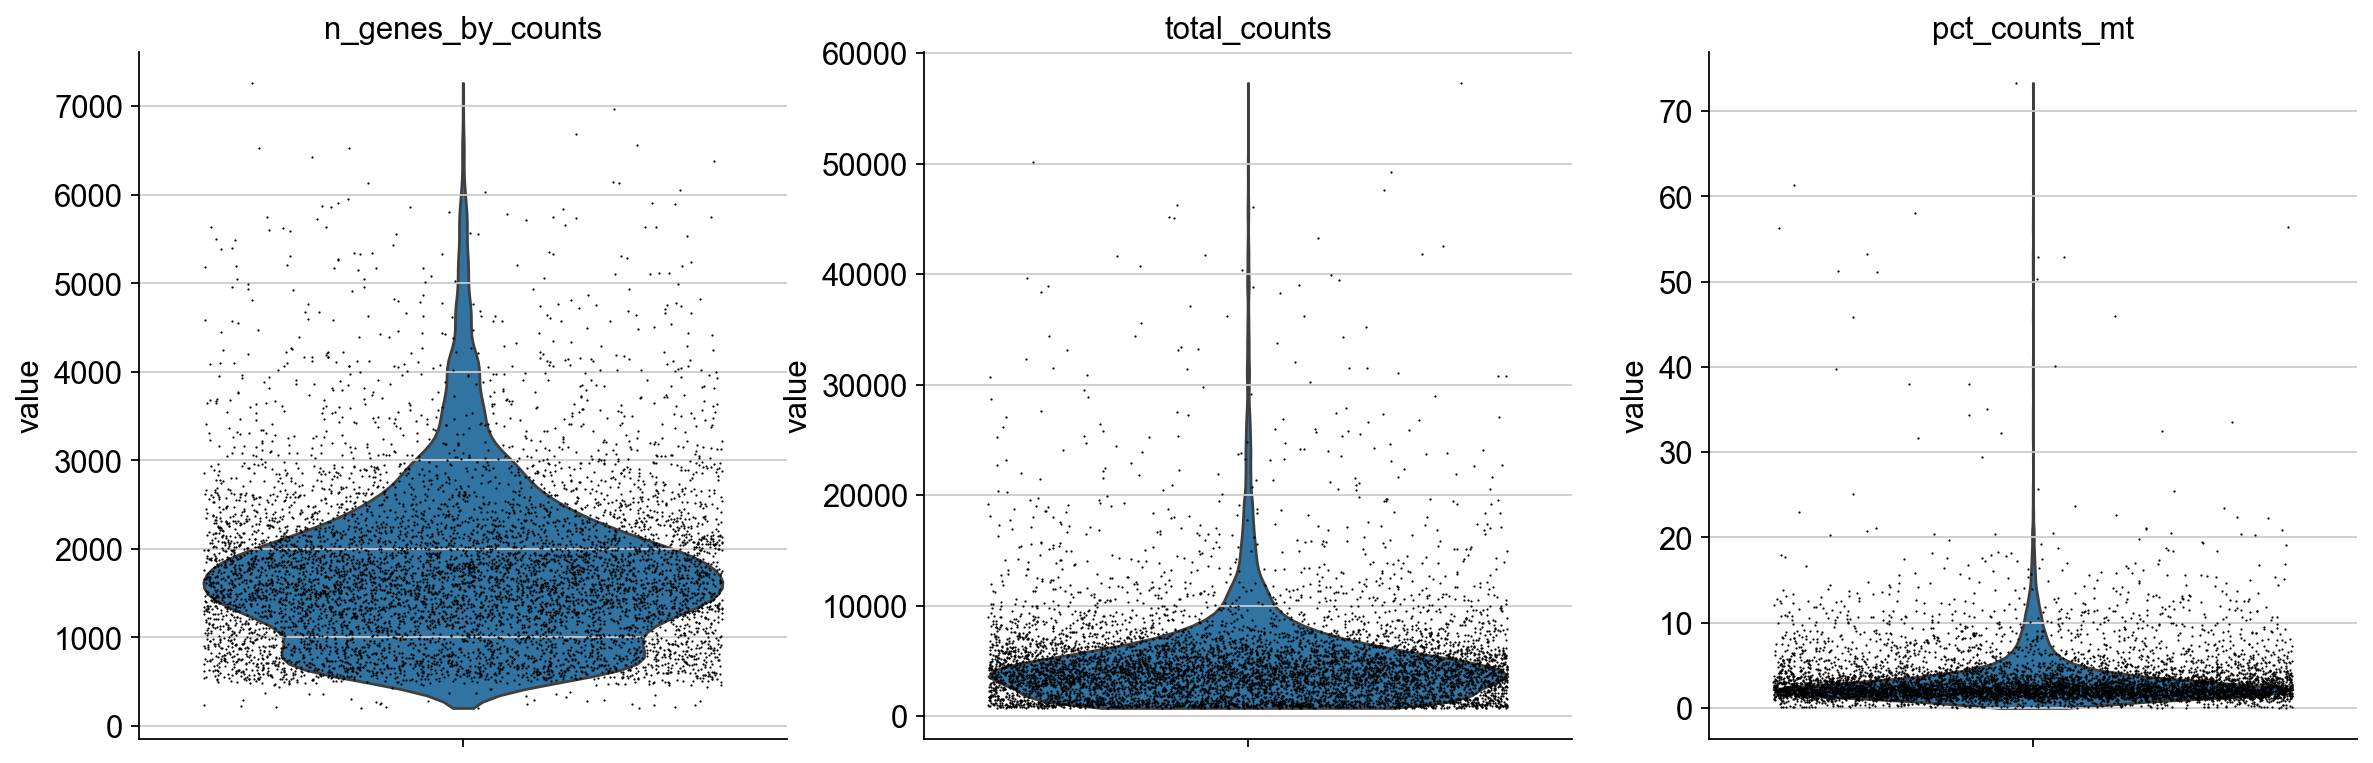

In [7]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

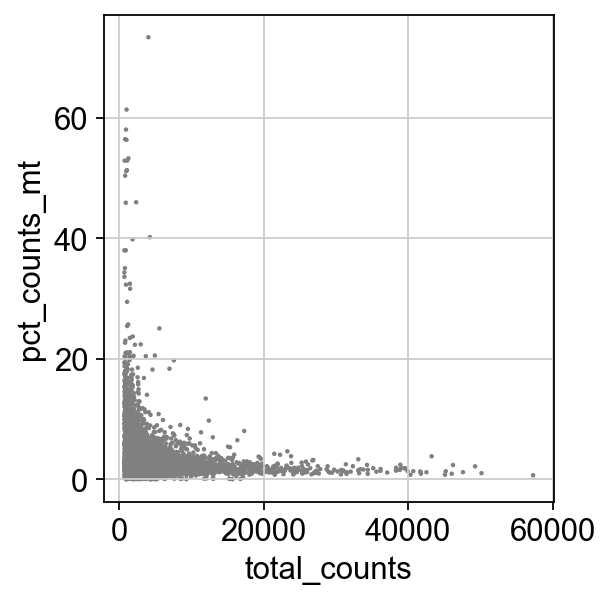

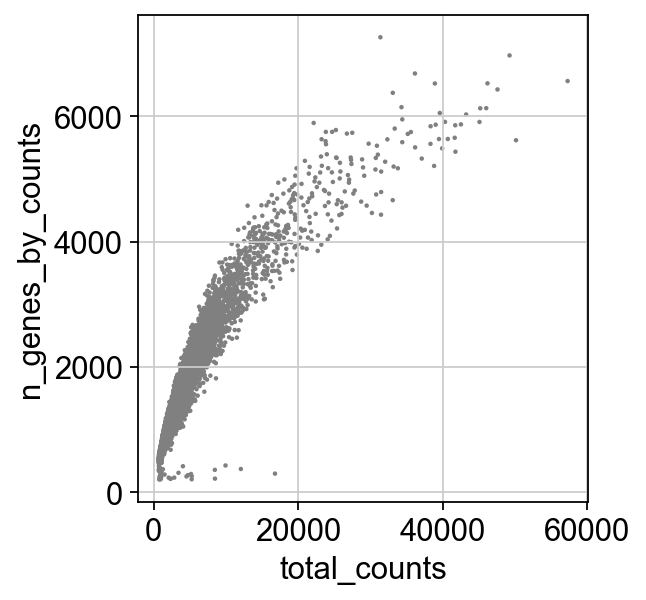

In [8]:
sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt")
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts")

Option filtering: remove cells with more than 4000 genes & more than 10% mitochondrial genes (not done in this analysis).

In [9]:
# adata = adata[adata.obs.n_genes_by_counts < 4000, :]
# adata = adata[adata.obs.pct_counts_mt < 10, :].copy()

Doublet detection using scrublet

In [10]:
sc.pp.scrublet(adata, batch_key="sample")

Running Scrublet
filtered out 1715 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.54
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 0.6%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 0.0%
filtered out 5403 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.

Normalize to 10,000 reads per cell

In [11]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.normalize_total(adata, target_sum=1e4)

normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)


Logarithmize the data

In [12]:
sc.pp.log1p(adata)

Calculate highly variable genes

In [13]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


Plot highly variable genes

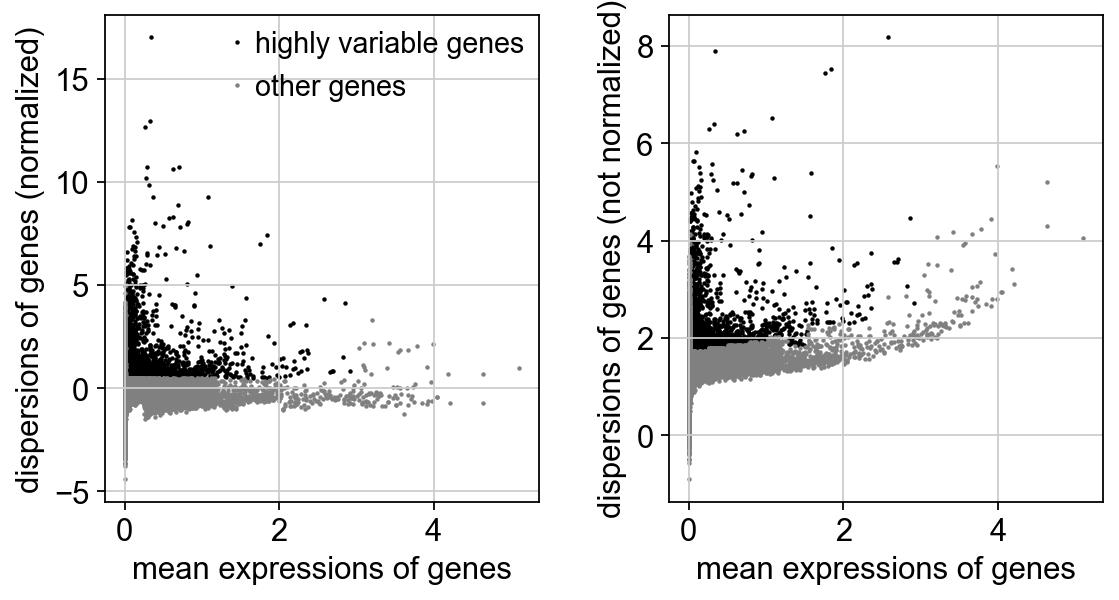

In [14]:
sc.pl.highly_variable_genes(adata)

# Clustering

Calculate PCA, UMAP and Leiden clusters

In [15]:
sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)

computing PCA
    with n_comps=50
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:07)
running Leiden clustering
    finished: found 12 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


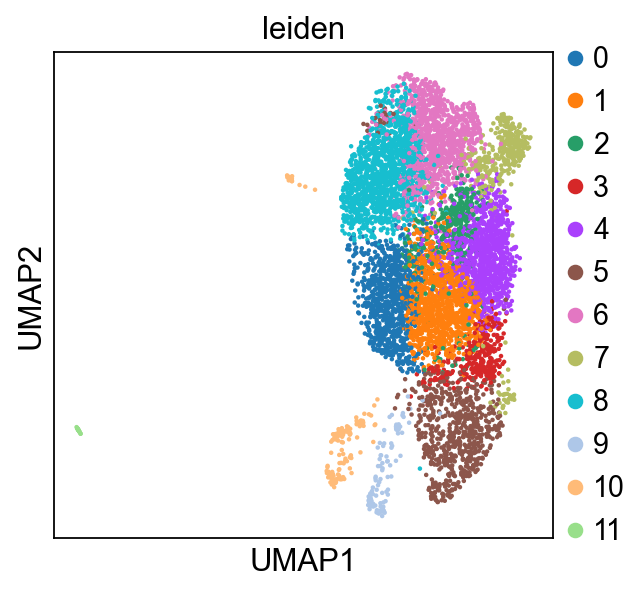

In [16]:
sc.pl.umap(adata, color=["leiden"])

Check QC metrics on clusters

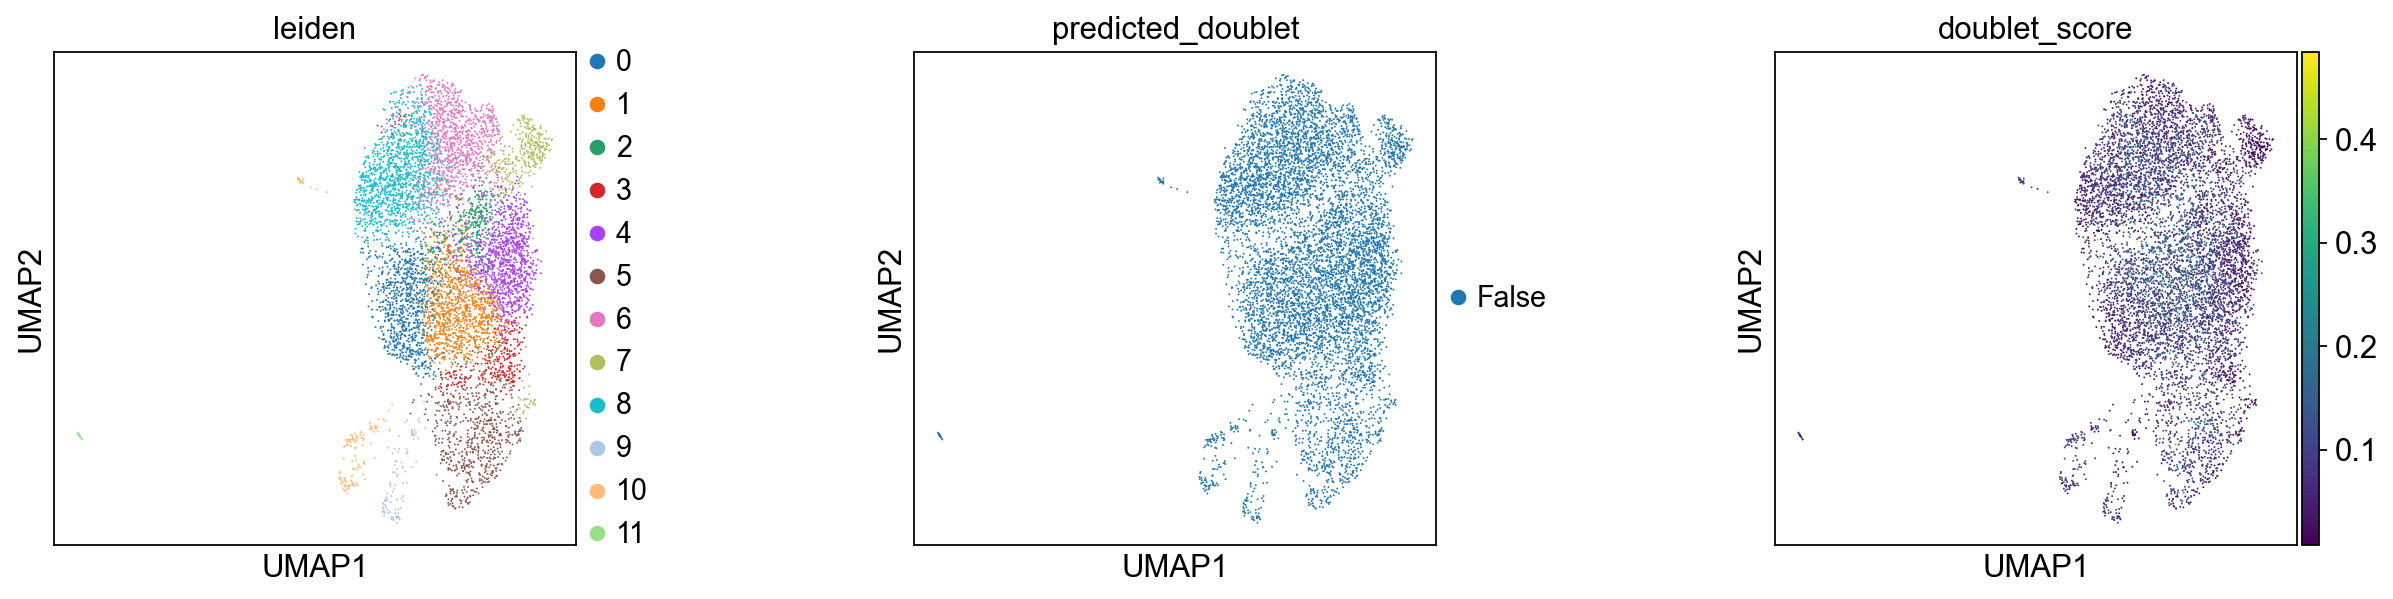

In [17]:
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    wspace=0.5,
    size=3,
)

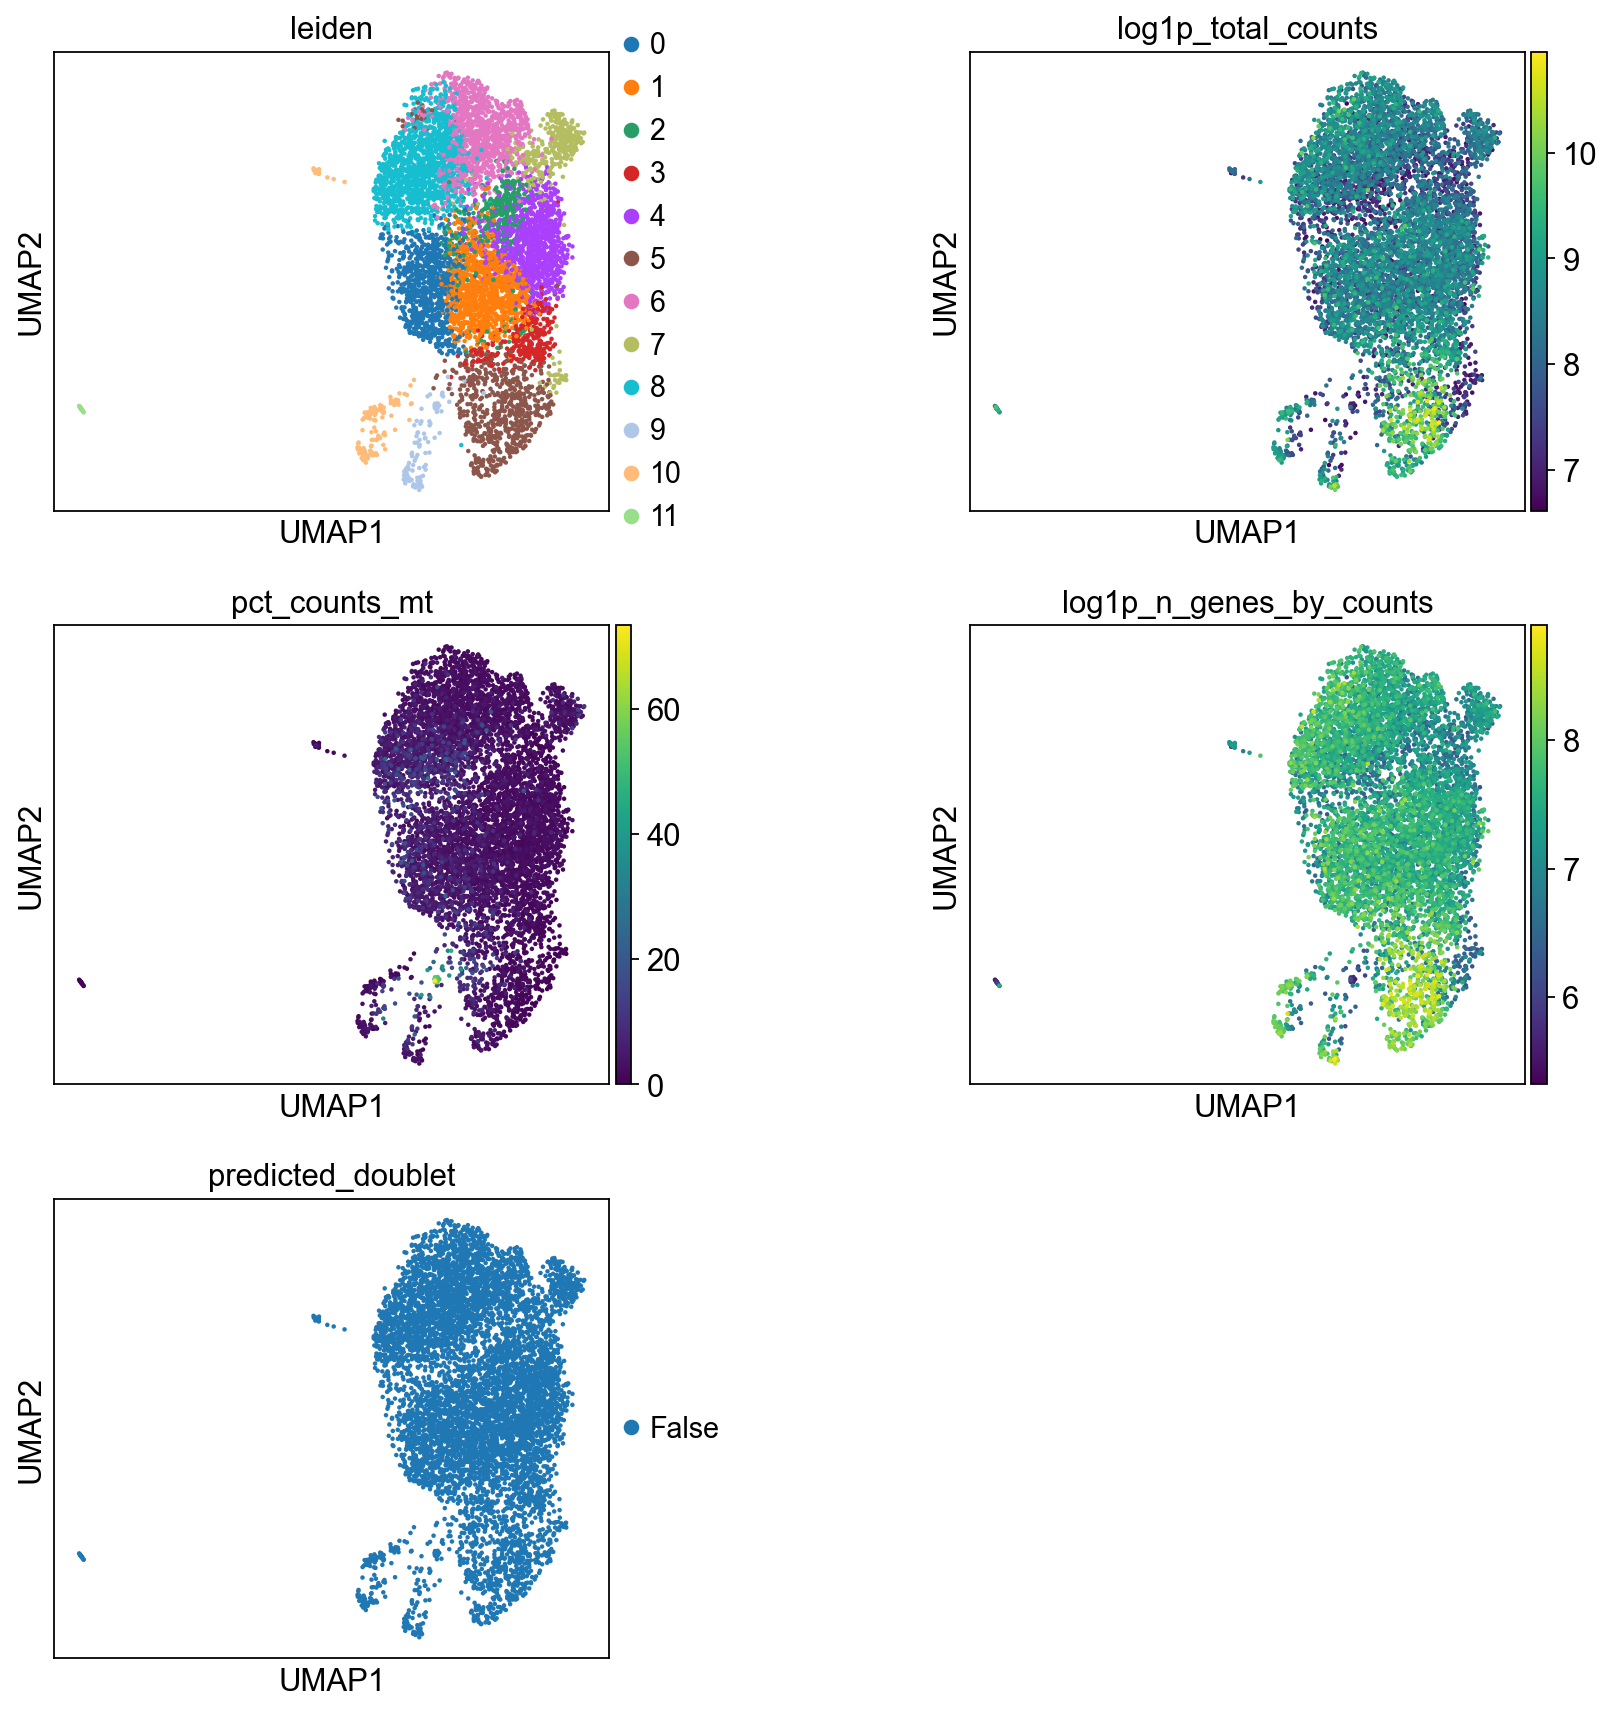

In [18]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts", "predicted_doublet"],
    wspace=0.5,
    ncols=2,
)

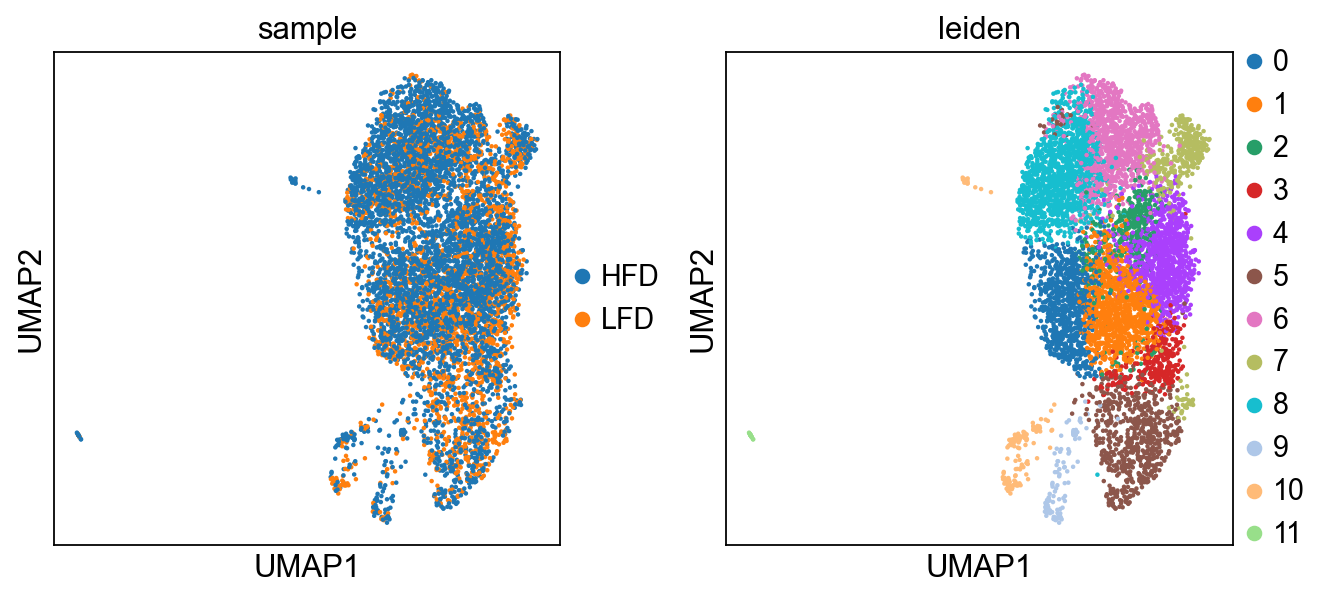

In [19]:
sc.pl.umap(adata, color=['sample', 'leiden'])

Remove doublets

In [20]:
adata = adata[adata.obs.predicted_doublet == False, :]

Save results file

In [21]:
# adata.write(results_file)

### Conclusions: 
1. We can see that there are doublets in the data, which should be removed.
2. Not many cells express high levels of mitochondrial genes, so we leave them in for now.

# Re-clustering after QC

In [22]:
# import h5ad file if starting from here
adata = sc.read_h5ad('cd4_sorted_260326.h5ad')

running Leiden clustering
    finished: found 13 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


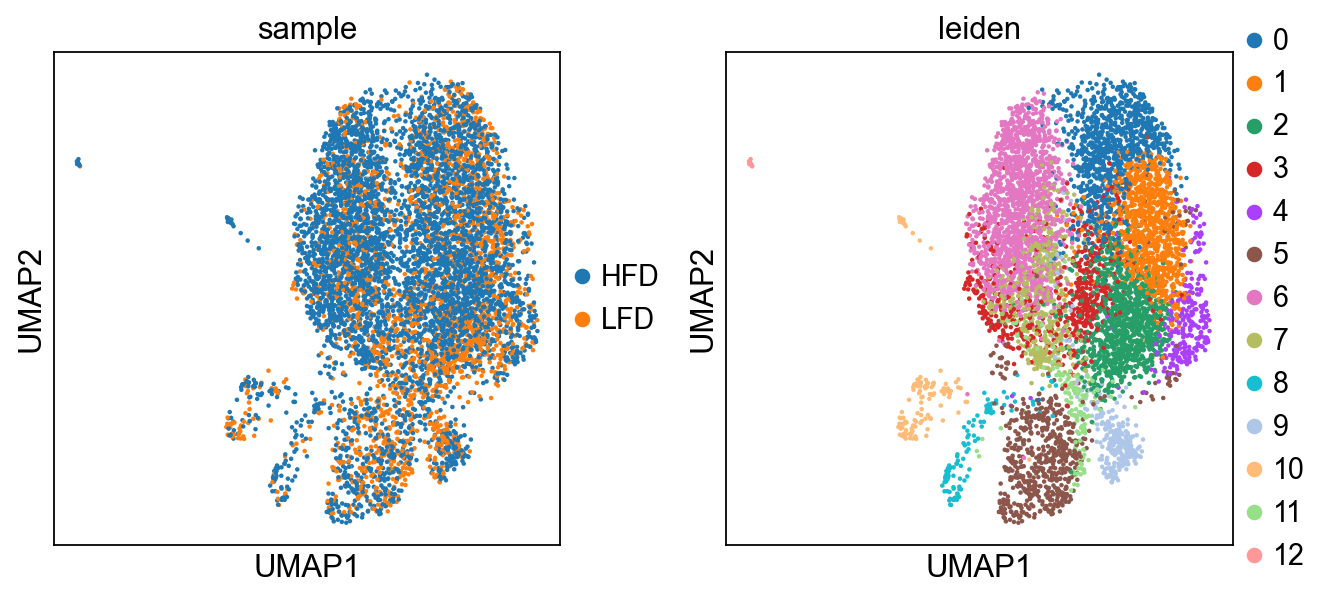

In [23]:
sc.tl.leiden(
    adata, resolution=1, flavor="igraph"
)
sc.pl.umap(adata, color=['sample', 'leiden'])

Calculate differentially expressed genes for each cluster

In [24]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:06)


    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden']`


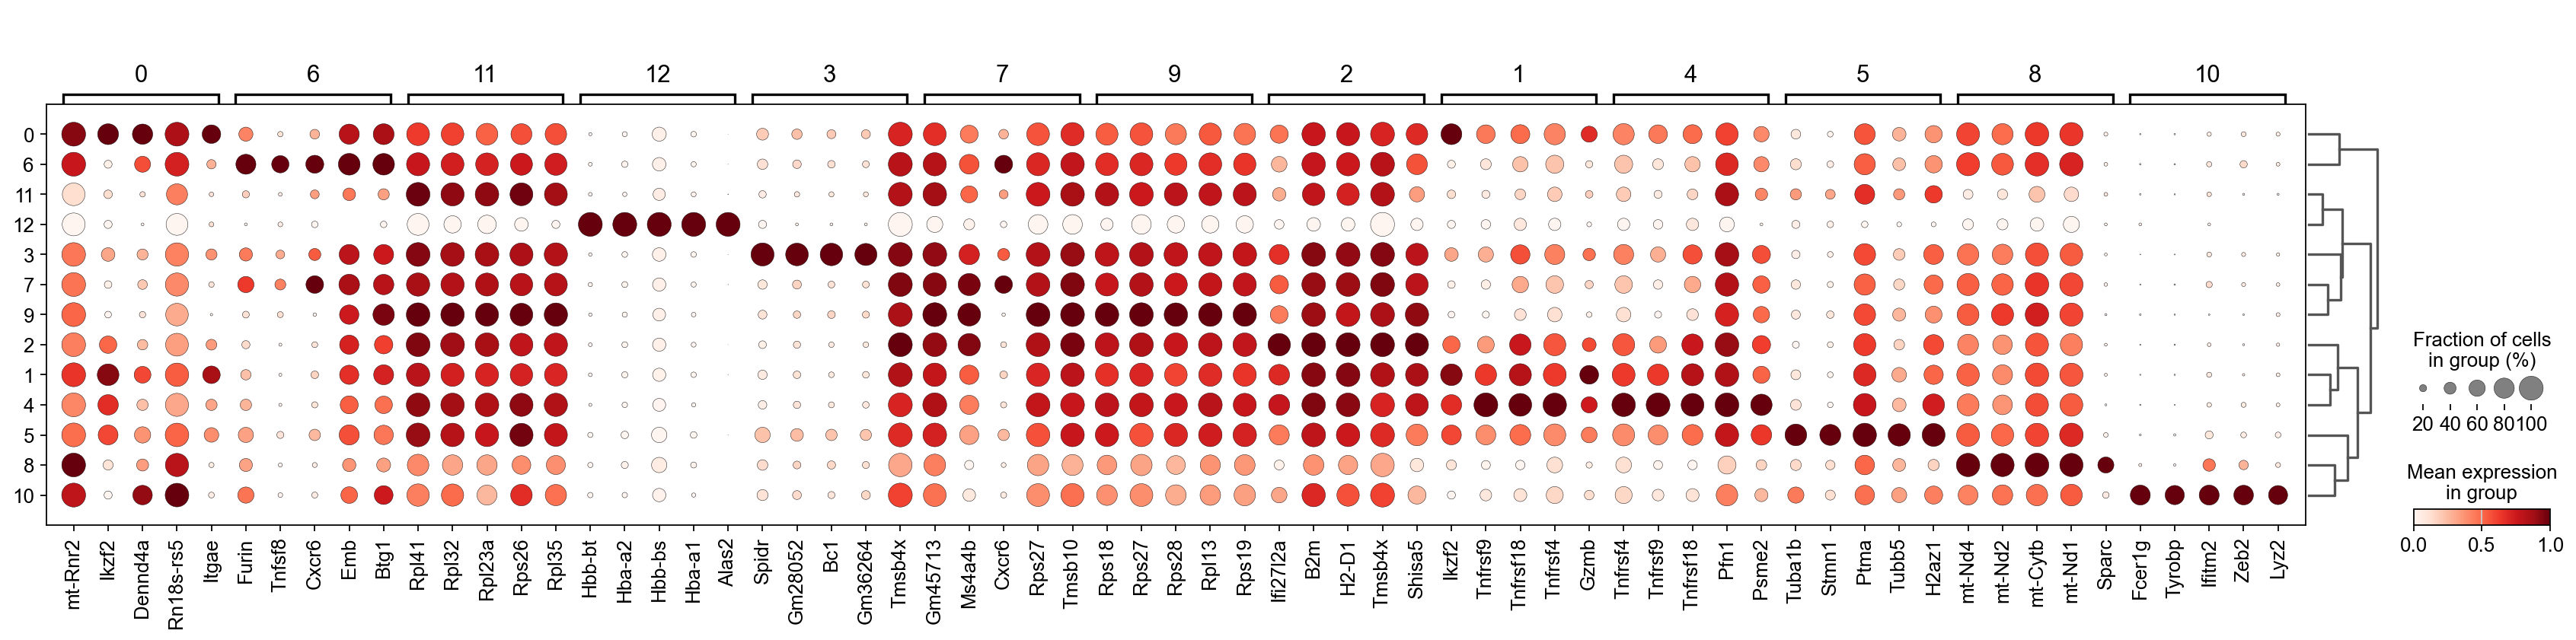

In [25]:
sc.pl.rank_genes_groups_dotplot(
    adata, groupby="leiden", standard_scale="var", n_genes=5
)

Clusters 8, 11 and 12 are likely contaminants and can be removed.

In [26]:
adata = adata[adata.obs['leiden'] != '10', :]
adata = adata[adata.obs['leiden'] != '8', :]
adata = adata[adata.obs['leiden'] != '12', :]

Recluster after removing cells with high mitochondrial contamination.

running Leiden clustering
    finished: found 13 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


/Users/scc/miniconda3/envs/scrnaseq/lib/python3.11/site-packages/scanpy/tools/_leiden.py:197: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_added] = pd.Categorical(


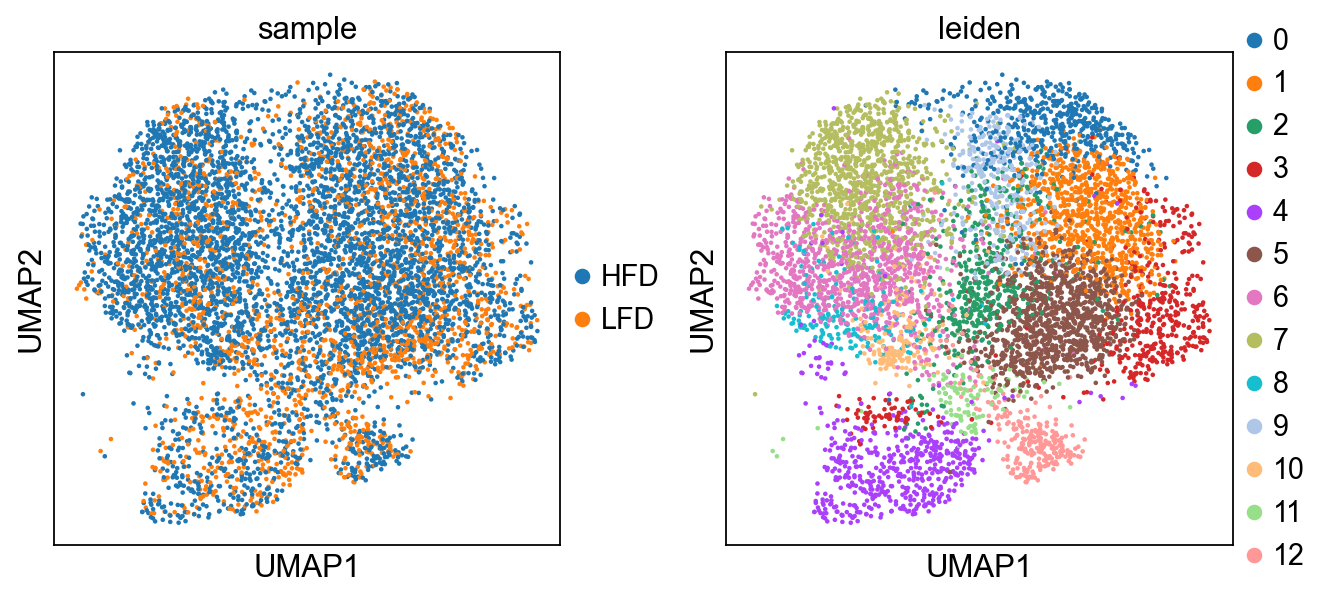

In [27]:
sc.tl.leiden(
    adata, resolution=1.1902, flavor="igraph"
)
sc.pl.umap(adata, color=['sample', 'leiden'])

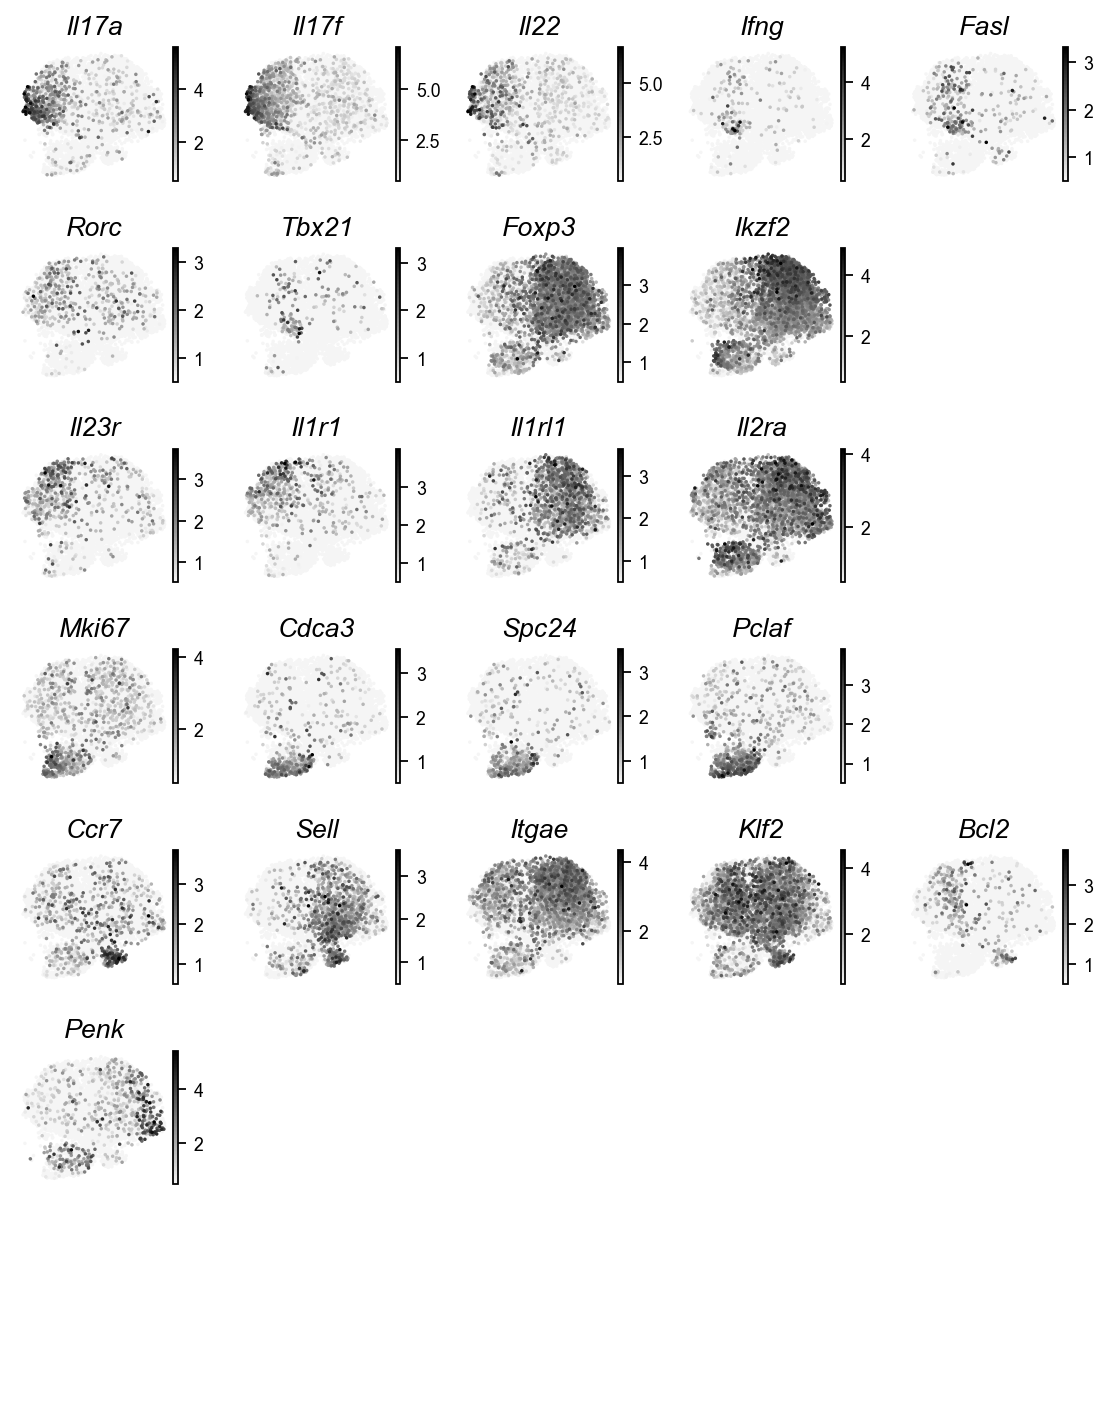

In [28]:
colors = ['whitesmoke', 'black']
n_bins = 100
cmap = LinearSegmentedColormap.from_list('custom_gray', colors, N=n_bins)

fig = plt.figure(figsize=(8.5, 11))

gs = fig.add_gridspec(7, 5, hspace=0.5, wspace=0.3)

# Define the layout 
row_layouts = [
    (0, 5),   
    (1, 4),   
    (2, 4),   
    (3, 4),   
    (4, 5),   
    (5, 1),
    (6, 0)
]

plt.rcParams['axes.labelsize'] = 8
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8

# Genes to plot
genes = ['Il17a', 'Il17f', 'Il22', 'Ifng', 'Fasl', 'Rorc', 'Tbx21', 'Foxp3', 'Ikzf2', 'Il23r', 'Il1r1', 'Il1rl1', 'Il2ra', 'Mki67', 'Cdca3', 'Spc24', 'Pclaf', 'Ccr7', 'Sell', 'Itgae', 'Klf2', 'Bcl2', 'Penk']

plot_idx = 0
for row, num_cols in row_layouts:
    for col in range(num_cols):
        if plot_idx < len(genes):
            # Create subplot at the specified position
            ax = fig.add_subplot(gs[row, col])
            
            # Plot UMAP with gene expression
            sc.pl.umap(adata, color=genes[plot_idx], ax=ax, show=False, 
                    color_map=cmap, vmin=0.5, vmax=None, size=10,
                    na_color='whitesmoke', use_raw=False, frameon=False, legend_loc='right margin')
            
            # Remove spines and axes
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['bottom'].set_visible(False)
            ax.spines['left'].set_visible(False)
            
            # Remove tick marks and labels
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlabel('')
            ax.set_ylabel('')
            
            # Set italic title
            ax.set_title(f'{genes[plot_idx]}', fontstyle='italic', fontsize=12)
            
            plot_idx += 1

for col in range(5):
    ax = fig.add_subplot(gs[6, col])
    ax.axis('off')

plt.savefig('umaps_genes_of_interest_smallerfont.svg', dpi=300, bbox_inches='tight')
plt.show()

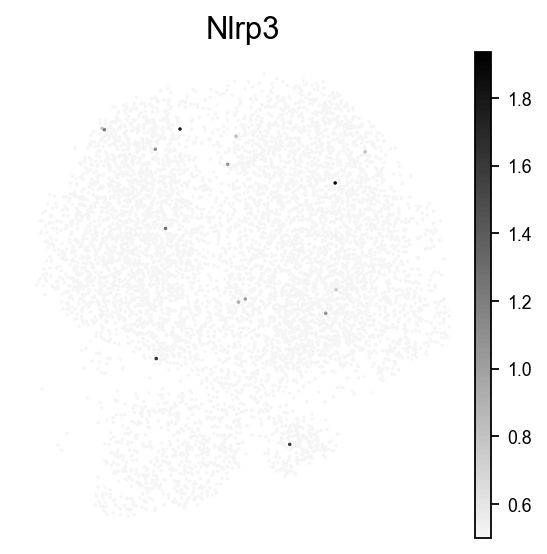

In [30]:
sc.pl.umap(
    adata,
    color='Nlrp3',
    cmap=cmap,
    vmin=0.5,
    size=10,
    na_color='whitesmoke',
    use_raw=False,
    frameon=False,
    legend_loc='right margin',
    title='Nlrp3',
)

# Cell type annotation

Clusters are annotated as subsets of CD4+ T cells based on the expression of marker genes per cluster.

In [29]:
cluster2annotation = {
     '0': 'Resident Treg',
     '1': 'Resident Treg',
     '2': 'Central Treg',
     '3': 'Penk+ Treg',
     '4': 'Proliferating Treg',
     '5': 'Central Treg',
     '6': 'Th17',
     '7': 'Th17',
     '8': 'Th17',
     '9': 'Resident Treg',
     '10': 'Th1',
     '11': 'Central Treg',
     '12': 'Naive',
}

Define custom color scheme

In [30]:
cluster_colors = {
    'Naive': '#37BE8F',
    'Th1': '#F255A9',
    'Th17': '#7DA13C',
    'Proliferating Treg': '#FF9127',
    'Resident Treg': '#FF5C55', 
    'Central Treg': '#34B7E2',
    'Penk+ Treg': '#9A60B0'
}

Add new cell type annotation

In [31]:
adata.obs['cell type'] = adata.obs['leiden'].map(cluster2annotation).astype('category')

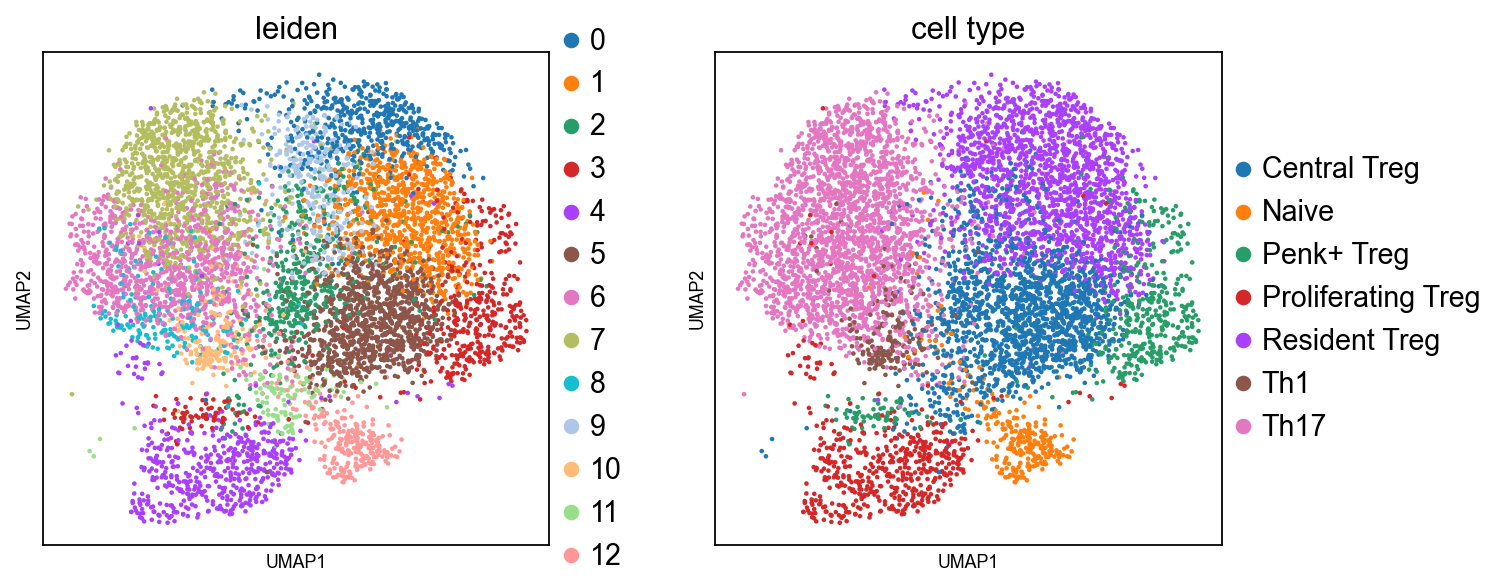

In [32]:
sc.pl.umap(adata, color=['leiden', 'cell type'])

# Plotting

### UMAP

Add new color scheme (Figure 2l)

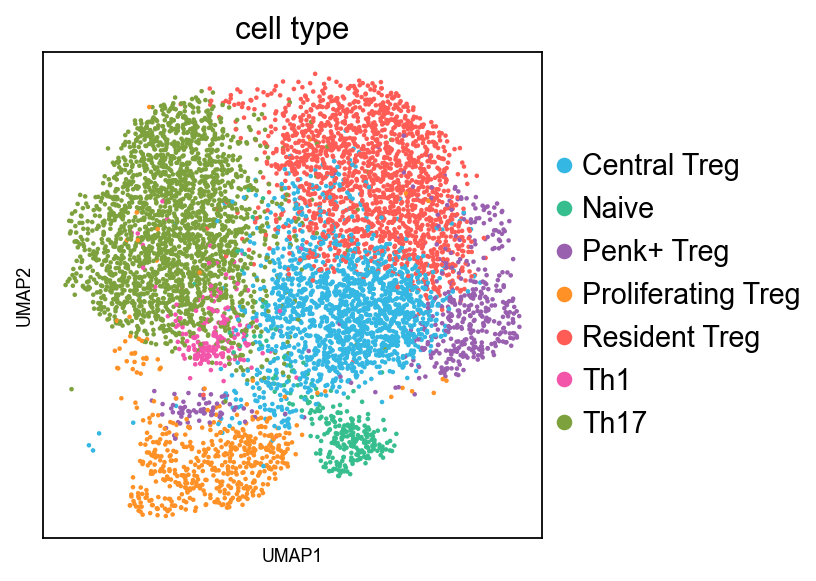

In [33]:
sc.pl.umap(adata, color='cell type', palette=cluster_colors, save='cell_type_umap.svg')

### Dotplots

In [ ]:
Extended Figure 5f

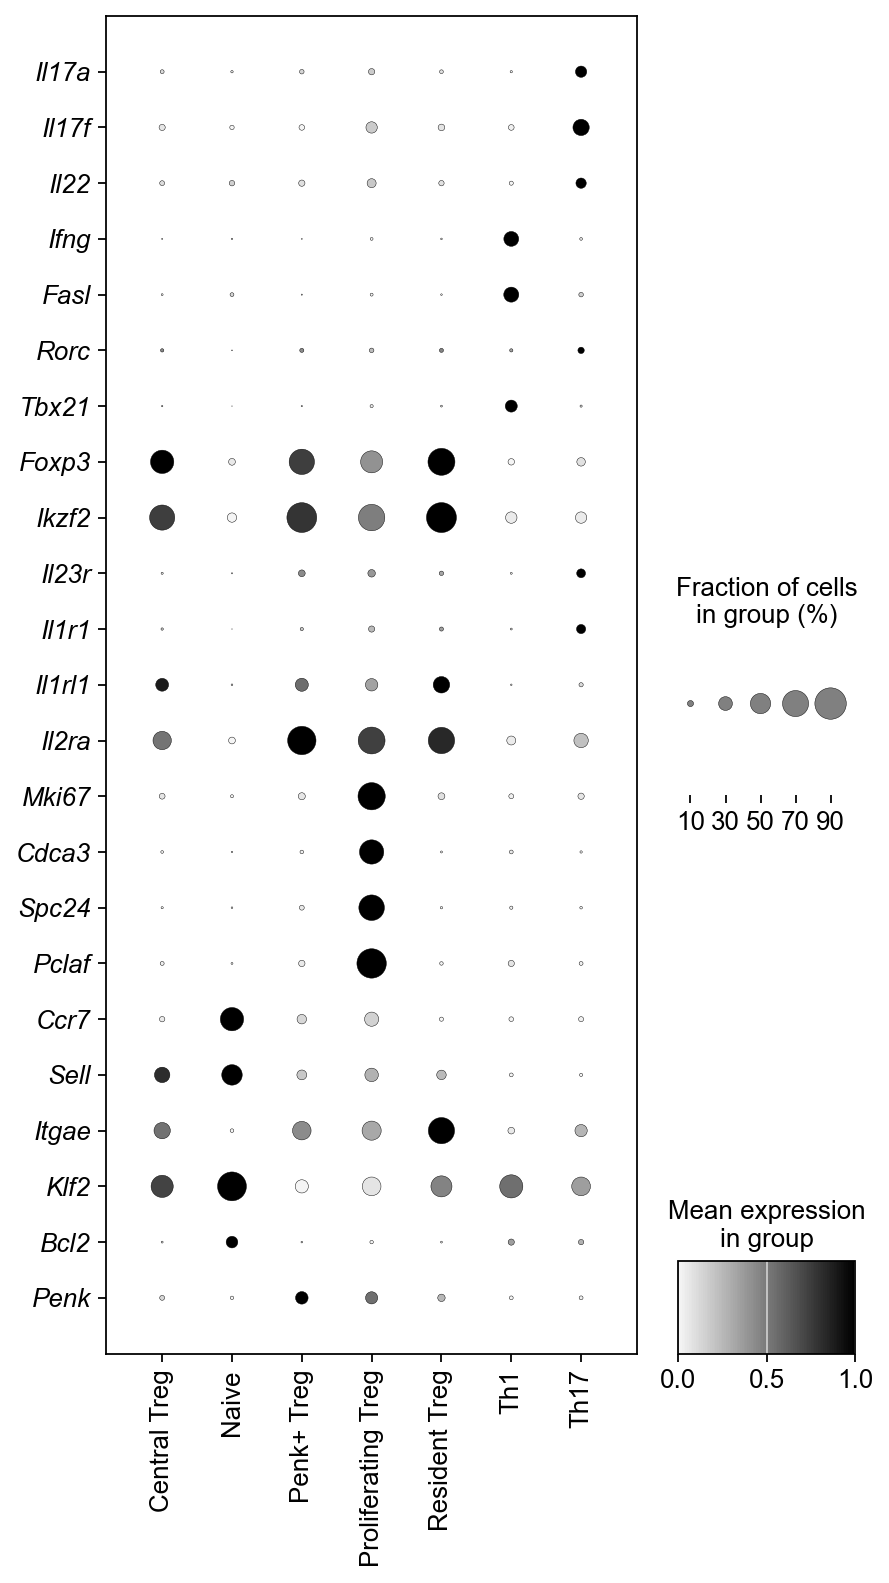

In [ ]:
colors = ['whitesmoke', 'black']
cmap = LinearSegmentedColormap.from_list('custom_gray', colors, N=100)

genes_of_interest = [
    'Il17a', 'Il17f', 'Il22', 'Ifng', 'Fasl',
    'Rorc', 'Tbx21', 'Foxp3', 'Ikzf2',
    'Il23r', 'Il1r1', 'Il1rl1', 'Il2ra',
    'Mki67', 'Cdca3', 'Spc24', 'Pclaf',
    'Ccr7', 'Sell', 'Itgae', 'Klf2',
    'Bcl2', 'Penk',
]

dp = sc.pl.dotplot(
    adata,
    var_names=genes_of_interest,
    groupby='cell type',
    use_raw=False,
    cmap=cmap,
    standard_scale='var',
    swap_axes=True,
    figsize=(6, 11),
    show=False,
    return_fig=True,
)
dp.make_figure()

for ax in dp.fig.get_axes():
    for label in ax.get_yticklabels():
        label.set_fontstyle('italic')

plt.savefig('dotplot_genes_of_interest.svg', dpi=300, bbox_inches='tight')
plt.show()

### Cell counts

Calculate cell type percentages per cluster, comparing HFD to LFD (used for Extended Data Figure 8a)

In [35]:
cell_type_counts = adata.obs.groupby(['sample', 'cell type']).size().unstack(fill_value=0)
cell_type_percentages = cell_type_counts.div(cell_type_counts.sum(axis=1), axis=0) * 100

/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/2053531404.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cell_type_counts = adata.obs.groupby(['sample', 'cell type']).size().unstack(fill_value=0)


In [36]:
print(f"{'Cell Type':<20} {'HFD (%)':<10} {'HFD (n)':<10} {'LFD (%)':<10} {'LFD (n)':<10} {'Difference (%)':<15}")
print("-" * 80)

for cell_type in cell_type_percentages.columns:
    hfd_pct = cell_type_percentages.loc['HFD', cell_type]
    lfd_pct = cell_type_percentages.loc['LFD', cell_type]
    hfd_count = cell_type_counts.loc['HFD', cell_type]
    lfd_count = cell_type_counts.loc['LFD', cell_type]
    difference = hfd_pct - lfd_pct
    print(f"{cell_type:<20} {hfd_pct:<10.2f} {hfd_count:<10} {lfd_pct:<10.2f} {lfd_count:<10} {difference:<15.2f}")

print("\nTotal cells per sample:")
print(f"HFD: {cell_type_counts.loc['HFD'].sum()}")
print(f"LFD: {cell_type_counts.loc['LFD'].sum()}")

Cell Type            HFD (%)    HFD (n)    LFD (%)    LFD (n)    Difference (%) 
--------------------------------------------------------------------------------
Central Treg         22.85      1156       25.15      506        -2.29          
Naive                3.30       167        5.37       108        -2.07          
Penk+ Treg           5.10       258        9.84       198        -4.74          
Proliferating Treg   5.97       302        11.03      222        -5.06          
Resident Treg        24.42      1235       25.55      514        -1.13          
Th1                  2.87       145        1.94       39         0.93           
Th17                 35.49      1795       21.12      425        14.37          

Total cells per sample:
HFD: 5058
LFD: 2012


### Il1r1 expression

Plot heatmap of Il1r1 expression comparing HFD and LFD (Figure 2m)

In [37]:
adata_hfd = adata[adata.obs['sample'] == 'HFD']
adata_lfd = adata[adata.obs['sample'] == 'LFD']

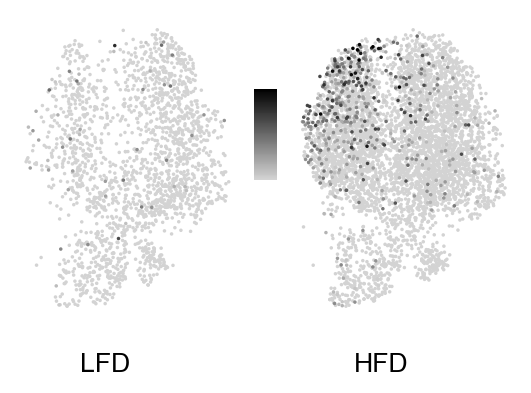

In [38]:
colors = ['lightgray', 'black']
n_bins = 100
cmap = LinearSegmentedColormap.from_list('custom_gray2', colors, N=n_bins)

fig = plt.figure(figsize=(4, 2.5))

gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.1, 1], hspace=0.3, wspace=0.1)

plt.rcParams['axes.labelsize'] = 8
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8

ax1 = fig.add_subplot(gs[0, 0])  # HFD plot
ax2 = fig.add_subplot(gs[0, 2])  # LFD plot
cbar_ax = fig.add_subplot(gs[0, 1]) 

# Plot LFD
sc.pl.umap(adata_lfd, color='Il1r1', ax=ax1, show=False, 
        color_map=cmap, vmin=0.5, vmax=3.5, size=10,
        na_color='lightgray', use_raw=False, frameon=False, legend_loc='right margin', colorbar_loc=None)


ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['bottom'].set_visible(False)
ax1.spines['left'].set_visible(False)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.set_title('')

# Plot HFD
sc.pl.umap(adata_hfd, color='Il1r1', ax=ax2, show=False, 
        color_map=cmap, vmin=0.5, vmax=3.5, size=10,
        na_color='lightgray', use_raw=False, frameon=False, legend_loc='right margin', colorbar_loc=None)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['bottom'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title('')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0.5, vmax=3.5))
sm.set_array([])
cbar = plt.colorbar(sm, cax=cbar_ax, orientation='vertical')

cbar_ax.set_position([cbar_ax.get_position().x0, cbar_ax.get_position().y0+0.35, 
                     cbar_ax.get_position().width, cbar_ax.get_position().height*0.3])


# Adjust color bar layout
cbar.outline.set_visible(False)
cbar.ax.set_yticks([])  # Remove ticks

fig.text(0.32, 0.02, 'LFD', ha='center', fontsize=12)
fig.text(0.75, 0.02, 'HFD', ha='center', fontsize=12)


plt.savefig('umaps_il1r1_hfd_lfd_notlabel.svg', dpi=300, bbox_inches='tight')
plt.show()

### Th17 cluster genes

Comparison of expression level within Th17 cluster (HFD vs. LFD) (Extended Data Figure 6b)

/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/2146853627.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_gene, x='Sample', y='Expression',
/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/2146853627.py:75: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().set_visible(False)
/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/2146853627.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_gene, x='Sample', y='Expression',
/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006

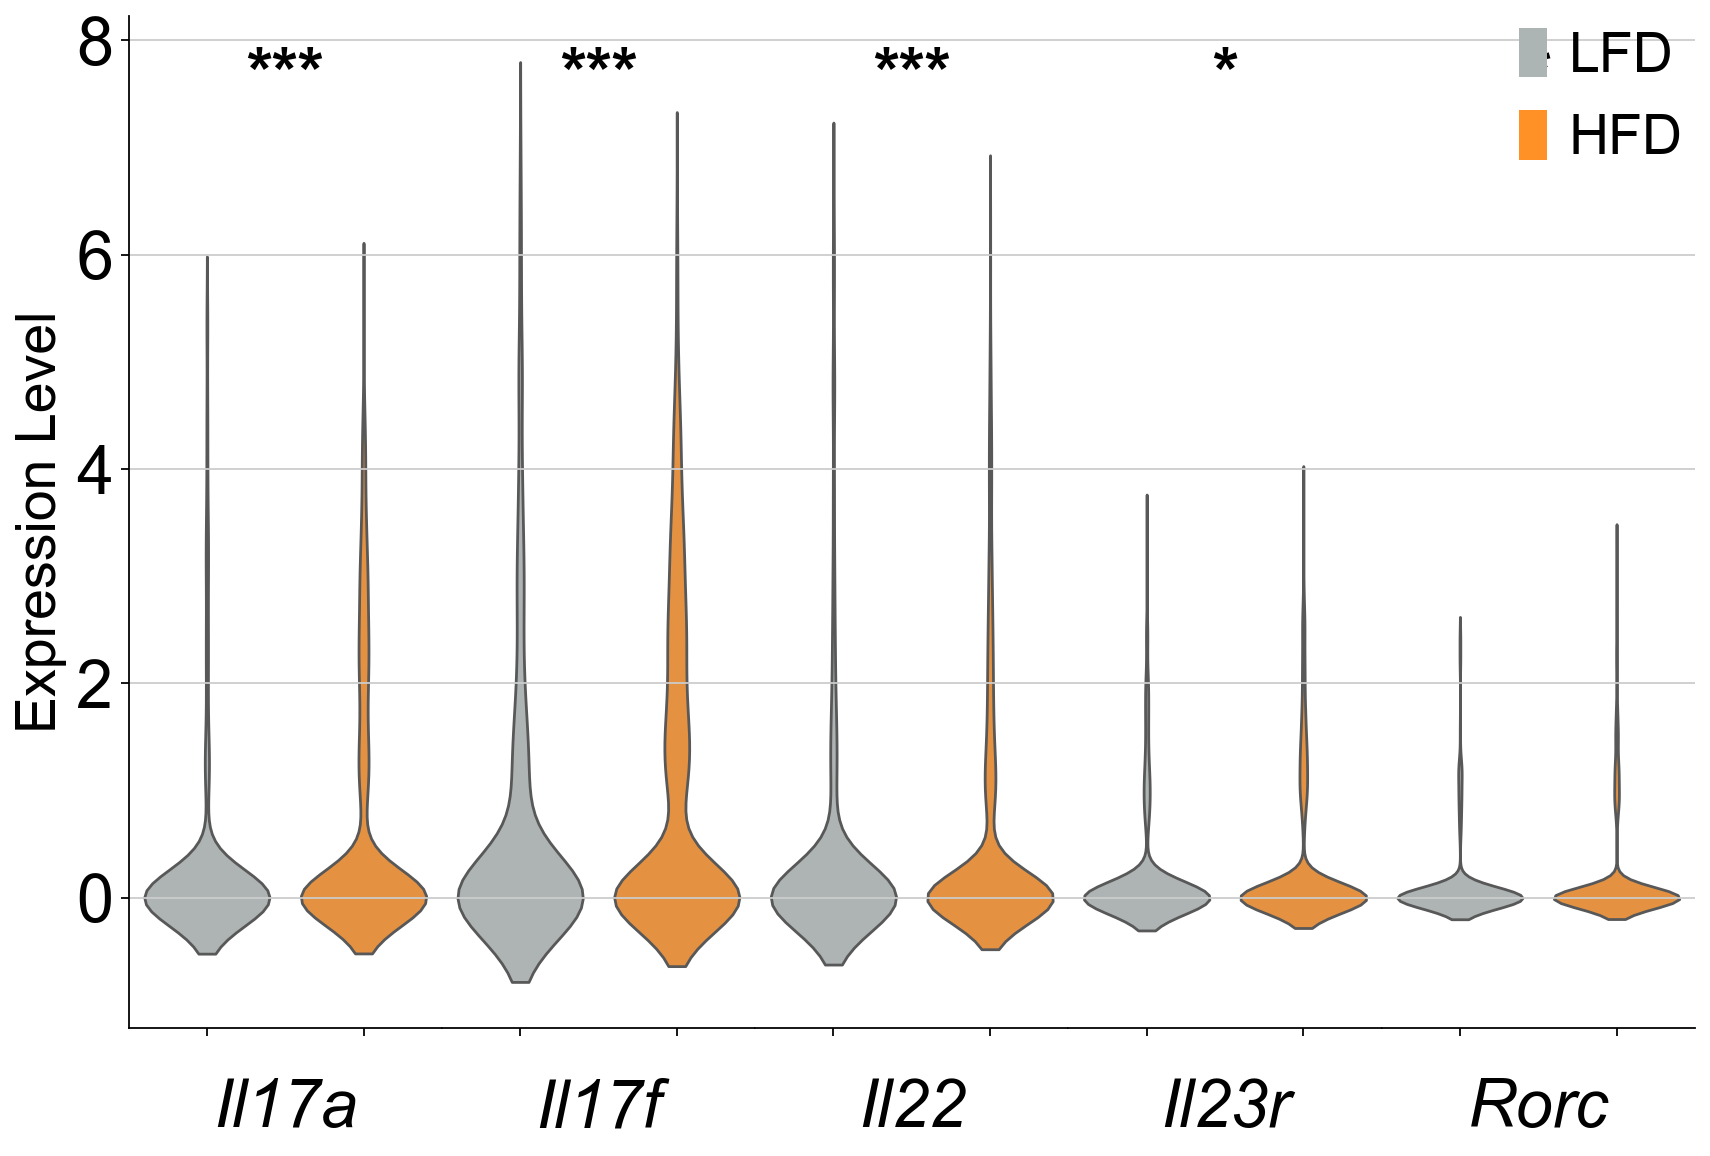

In [39]:
th17_cells = adata[adata.obs['cell type'] == 'Th17'].copy()

# Genes to plot
genes = ['Il17a', 'Il17f', 'Il22', 'Il23r', 'Rorc']

# Create subplots 
fig, axes = plt.subplots(1, 5, figsize=(10.5, 7), sharey=True)
fig.subplots_adjust(wspace=0) 

# Determine global y-axis limits
all_expression_data = []
for gene in genes:
    for sample in ['HFD', 'LFD']:
        sample_cells = th17_cells[th17_cells.obs['sample'] == sample]
        if gene in sample_cells.var_names:
            expression = sample_cells[:, gene].X.toarray().flatten()
            all_expression_data.extend(expression)

# Set global y-axis limits 
y_min = min(all_expression_data)
y_max = max(all_expression_data)
y_padding = (y_max - y_min) * 0.1
y_lim = [y_min - y_padding, y_max + y_padding]

for i, gene in enumerate(genes):
    ax = axes[i]
    
    plot_data = []
    for sample in ['LFD', 'HFD']:
        sample_cells = th17_cells[th17_cells.obs['sample'] == sample]
        if gene in sample_cells.var_names:
            expression = sample_cells[:, gene].X.toarray().flatten()
            for expr in expression:
                plot_data.append({
                    'Sample': sample,
                    'Expression': expr
                })
    
    df_gene = pd.DataFrame(plot_data)
    
    sns.violinplot(data=df_gene, x='Sample', y='Expression', 
                   palette={'LFD': '#acb5b4', 'HFD': '#FF9127'},
                   ax=ax, width=0.8, inner=None)  
    
    hfd_data = df_gene[df_gene['Sample'] == 'HFD']['Expression']
    lfd_data = df_gene[df_gene['Sample'] == 'LFD']['Expression']
    statistic, p_value = stats.mannwhitneyu(hfd_data, lfd_data, alternative='two-sided')
    
    if p_value < 0.001:
        sig_text = '***'
    elif p_value < 0.01:
        sig_text = '**'
    elif p_value < 0.05:
        sig_text = '*'
    else:
        sig_text = 'ns'
    
    ax.text(0.5, y_max * 1.05, sig_text, ha='center', va='bottom', 
            fontsize=30, fontweight='bold')
    
    ax.set_xlabel('', fontsize=30)
    ax.set_ylabel('', fontsize=30)
    ax.tick_params(axis='x', labelsize=30)
    ax.tick_params(axis='y', labelsize=30)
    
    ax.set_xticklabels([])
    
    if i > 0:
        ax.spines['left'].set_visible(False)
        ax.tick_params(axis='y', left=False, labelleft=False)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.legend().set_visible(False)

axes[0].set_ylabel('Expression Level', fontsize=25)

for i, gene in enumerate(genes):
    axes[i].text(0.5, -0.05, gene, ha='center', va='top', 
                transform=axes[i].transAxes, fontstyle='italic', fontsize=30)

# Custom legend
legend_elements = [Patch(facecolor='#acb5b4', label='LFD'),
                   Patch(facecolor='#ff9127', label='HFD')]
fig.legend(handles=legend_elements, loc='upper right', fontsize=25)

plt.tight_layout(pad=0)
plt.savefig('th17_violin_plots_hfd_lfd.svg', dpi=300, bbox_inches='tight')
plt.show()

In [40]:
pval_results = []

for gene in genes:
    plot_data = []

    for sample in ['LFD', 'HFD']:
        sample_cells = th17_cells[th17_cells.obs['sample'] == sample]

        if gene in sample_cells.var_names:
            x = sample_cells[:, gene].X
            expression = x.toarray().flatten() if hasattr(x, "toarray") else np.asarray(x).flatten()

            for expr in expression:
                plot_data.append({
                    'Sample': sample,
                    'Expression': expr
                })

    df_gene = pd.DataFrame(plot_data)

    hfd_data = df_gene[df_gene['Sample'] == 'HFD']['Expression']
    lfd_data = df_gene[df_gene['Sample'] == 'LFD']['Expression']

    statistic, p_value = stats.mannwhitneyu(
        hfd_data,
        lfd_data,
        alternative='two-sided'
    )

    pval_results.append({
        'Gene': gene,
        'n_LFD': len(lfd_data),
        'n_HFD': len(hfd_data),
        'U_statistic': statistic,
        'p_value': p_value,
        'significance': (
            '***' if p_value < 0.001 else
            '**' if p_value < 0.01 else
            '*' if p_value < 0.05 else
            'ns'
        )
    })

pvals_df = pd.DataFrame(pval_results)

print(
    pvals_df.to_string(
        index=False,
        formatters={'p_value': '{:.3e}'.format}
    )
)

 Gene  n_LFD  n_HFD  U_statistic   p_value significance
Il17a    425   1795     440705.5 1.344e-11          ***
Il17f    425   1795     442520.0 3.388e-09          ***
 Il22    425   1795     413429.0 1.314e-04          ***
Il23r    425   1795     401077.0 1.080e-02            *
 Rorc    425   1795     397448.5 1.227e-02            *


### DEG

Volcano plot comparing genes expressed in Th17 cluster, comparing HFD and LFD (Extended Data Figure 6d)

In [41]:
# Filter for Th17 cells only
th17_cells = adata[adata.obs['cell type'] == 'Th17'].copy()

min_cells = 100
n_cells_expressing = (th17_cells.X > 0).sum(axis=0)
genes_to_keep = np.asarray(n_cells_expressing >= min_cells).flatten()
th17_cells = th17_cells[:, genes_to_keep].copy()


# Perform differential expression 
sc.tl.rank_genes_groups(
    th17_cells, 
    groupby='sample', 
    method='wilcoxon',
    use_raw=False,
    tie_correct=True,  
    rankby_abs=False
)

result = th17_cells.uns['rank_genes_groups']
groups = result['names'].dtype.names

# Create DataFrame
df_results = pd.DataFrame({
    'gene': result['names']['HFD'],
    'logfoldchanges': result['logfoldchanges']['HFD'],
    'pvals': result['pvals']['HFD'],
    'pvals_adj': result['pvals_adj']['HFD'],
    'scores': result['scores']['HFD']
})

# Remove genes with NaN values
df_results = df_results.dropna()

# Additional filtering to match R's approach
df_results = df_results[
    (df_results['logfoldchanges'].abs() > 0.25) 
].copy()

# Calculate -log10(pvals_adj)
df_results['-log10_padj'] = -np.log10(df_results['pvals_adj'])

# Filter out extreme outliers
df_filtered = df_results[
    (df_results['logfoldchanges'].abs() <= 6) &
    (df_results['-log10_padj'] <= 25) &
    (df_results['pvals_adj'] > 1e-25)
].copy()

pval_threshold = 0.0001
logfc_threshold = 1.0

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:01)


Save to csv

In [42]:
df_filtered.to_csv("differential_expression_th17_hfd_lfd.csv")

### Volcano plot

Extended Data Figure 6d

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


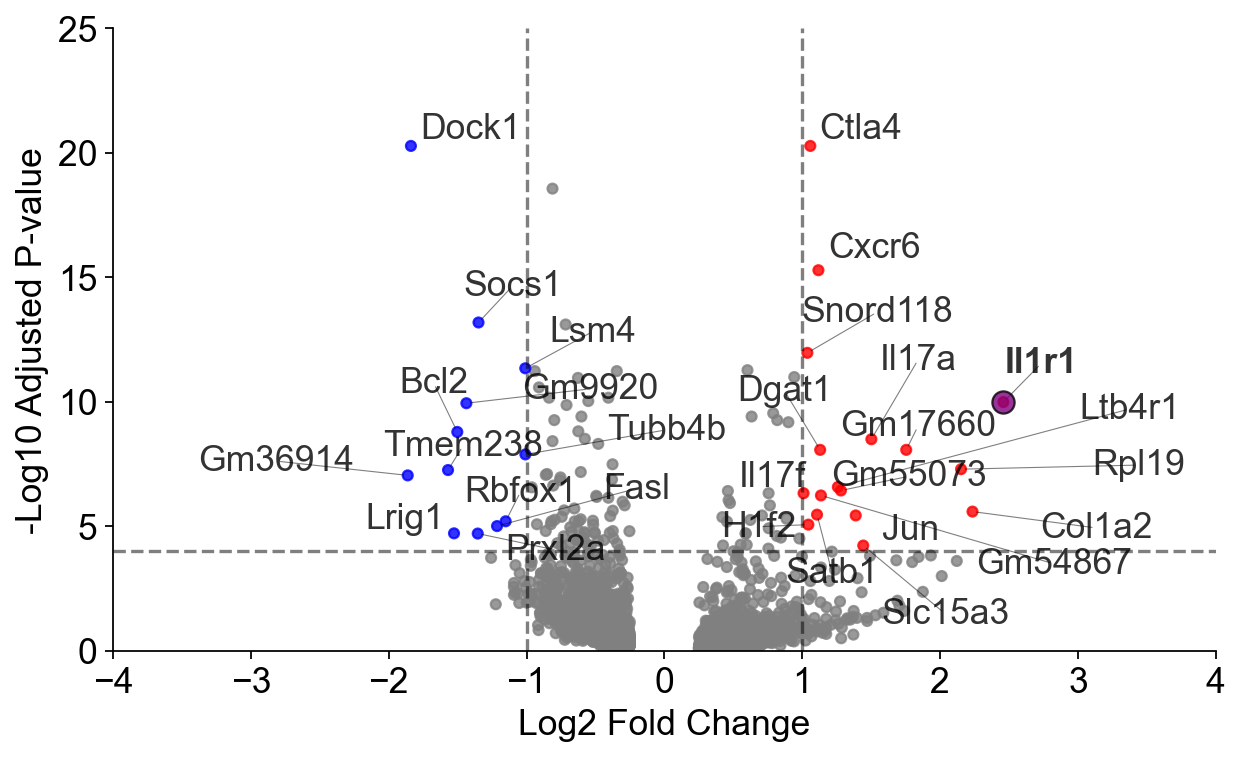

In [43]:
# Create volcano plot
fig, ax = plt.subplots(figsize=(8, 5))

# Color points
colors = []
for i, row in df_filtered.iterrows():
    if row['pvals_adj'] < pval_threshold and abs(row['logfoldchanges']) > logfc_threshold:
        if row['logfoldchanges'] > 0:
            colors.append('red')
        else:
            colors.append('blue')
    else:
        colors.append('gray')

# Scatter plot
scatter = ax.scatter(df_filtered['logfoldchanges'], df_filtered['-log10_padj'], 
                    c=colors, alpha=0.8, s=20)

# Highlight Il1r1
il1r1_data = df_filtered[df_filtered['gene'] == 'Il1r1']
if not il1r1_data.empty:
    ax.scatter(il1r1_data['logfoldchanges'], il1r1_data['-log10_padj'], 
              c='purple', s=100, alpha=0.8, edgecolors='black', linewidth=1, zorder=5)

# Significance lines
ax.axhline(y=-np.log10(pval_threshold), color='black', linestyle='--', alpha=0.5)
ax.axvline(x=logfc_threshold, color='black', linestyle='--', alpha=0.5)
ax.axvline(x=-logfc_threshold, color='black', linestyle='--', alpha=0.5)

# Axis limits
ax.set_xlim(-4, 4)
ax.set_ylim(0, 25)

# Remove spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Label significant genes
significant_genes = df_filtered[
    ((df_filtered['pvals_adj'] < pval_threshold) & (abs(df_filtered['logfoldchanges']) > logfc_threshold)) |
    (df_filtered['gene'] == 'Il1r1')
]

texts = []
for _, row in significant_genes.iterrows():
    text = ax.annotate(row['gene'], 
                      (row['logfoldchanges'], row['-log10_padj']),
                      fontsize=16, alpha=0.8,
                      fontweight='bold' if row['gene'] == 'Il1r1' else 'normal')
    texts.append(text)

# Adjust text
adjust_text(texts, ax=ax, 
           arrowprops=dict(arrowstyle='-', color='black', alpha=0.5, lw=0.5),
           expand_points=(1.5, 1.5),
           expand_text=(1.2, 1.2),
           force_text=(0.2, 0.2),
           force_points=(0.2, 0.2))

# Labels
ax.set_xlabel('Log2 Fold Change', fontsize=16)
ax.set_ylabel('-Log10 Adjusted P-value', fontsize=16)
ax.tick_params(axis='both', labelsize=16)


ax.grid(False)

plt.tight_layout()
plt.savefig('th17_volcano_plot_hfd_lfd.svg', dpi=300, bbox_inches='tight')
plt.show()

### Th17 pathogenicity score

Calculate and plot Th17 pathogenicity score (Extended Data Figure 6c)

Found 123 genes in Th17 cells
computing score 'Th17_Pathogenicity_Score'
    finished: added
    'Th17_Pathogenicity_Score', score of gene set (adata.obs).
    1179 total control genes are used. (0:00:00)


/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/3063319287.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=plot_data, x='sample', y='score',


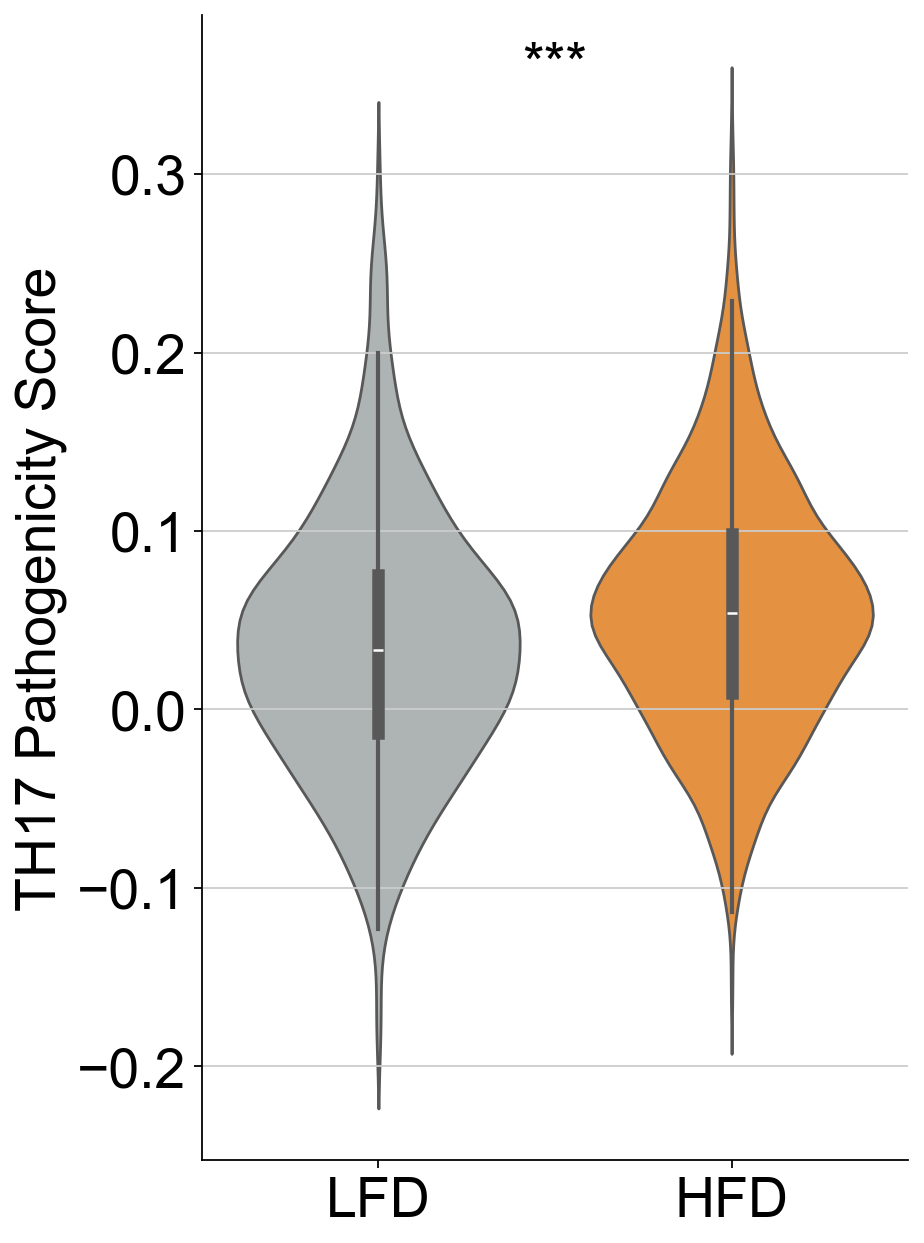

p-value: 3.6106e-08


In [44]:
# Load the combined gene list
df = pd.read_excel('Combined_Gene_List.xlsx')

# Convert gene names to have only the first letter capitalized
def convert_gene_name(gene_name):
    return gene_name[0].upper() + gene_name[1:].lower()

df['Gene'] = df['Gene'].apply(convert_gene_name)
combined_genes = df['Gene'].unique().tolist()

# Get genes that are found in the Th17 cluster
th17_genes = th17_cells.var_names.tolist()
combined_genes_found = [gene for gene in combined_genes if gene in th17_genes]

# Check if there are enough genes
if len(combined_genes_found) < 2:
    print("Not enough combined genes found in the object")
else:
    print(f"Found {len(combined_genes_found)} genes in Th17 cells")
    
    # Calculate Th17 pathogenicity score
    sc.tl.score_genes(th17_cells, combined_genes_found, score_name='Th17_Pathogenicity_Score')
    
    # Prepare data for plotting
    plot_data = pd.DataFrame({
        'sample': th17_cells.obs['sample'].values,
        'score': th17_cells.obs['Th17_Pathogenicity_Score'].values
    })
    
    # Perform statistical test
    hfd_scores = plot_data[plot_data['sample'] == 'HFD']['score']
    lfd_scores = plot_data[plot_data['sample'] == 'LFD']['score']
    _, p_val = mannwhitneyu(hfd_scores, lfd_scores, alternative='two-sided')
    
    # Determine significance
    if p_val < 0.001:
        significance = '***'
    elif p_val < 0.01:
        significance = '**'
    elif p_val < 0.05:
        significance = '*'
    else:
        significance = 'ns'
    
    # Create violin plot
    fig, ax = plt.subplots(figsize=(6, 8))
    
    sns.violinplot(data=plot_data, x='sample', y='score', 
                   order=['LFD', 'HFD'],
                   palette={'LFD': '#acb5b4', 'HFD': '#ff9127'}, ax=ax)
    
    ax.set_xlabel('', fontsize=25)
    ax.set_ylabel('TH17 Pathogenicity Score', fontsize=25)
    ax.tick_params(axis='both', labelsize=25)
    
    sns.despine()
    
    # Add significance annotation
    y_max = plot_data['score'].max()
    ax.text(0.5, y_max * 1.05, significance, 
            ha='center', va='bottom', fontsize=25, color='black')
    
    plt.tight_layout()
    plt.savefig('th17_pathogenicity_violin_plot.svg', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"p-value: {p_val:.4e}")

### Th17 genes in Il1r1+ and - cells

Extended Data Figure 6f

In [45]:
il1r1_expression = th17_cells[:, 'Il1r1'].X.toarray().flatten()
th17_cells.obs['Il1r1_status'] = ['Il1r1+' if expr > 0 else 'Il1r1-' for expr in il1r1_expression]

# Define colors
il1r1_colors = {'Il1r1-': '#2f88ca', 'Il1r1+': '#f43a22'}

/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/3835297426.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_gene, x='Il1r1_status', y='Expression',
/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/3835297426.py:74: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().set_visible(False)
/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/3835297426.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_gene, x='Il1r1_status', y='Expression',
/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipy

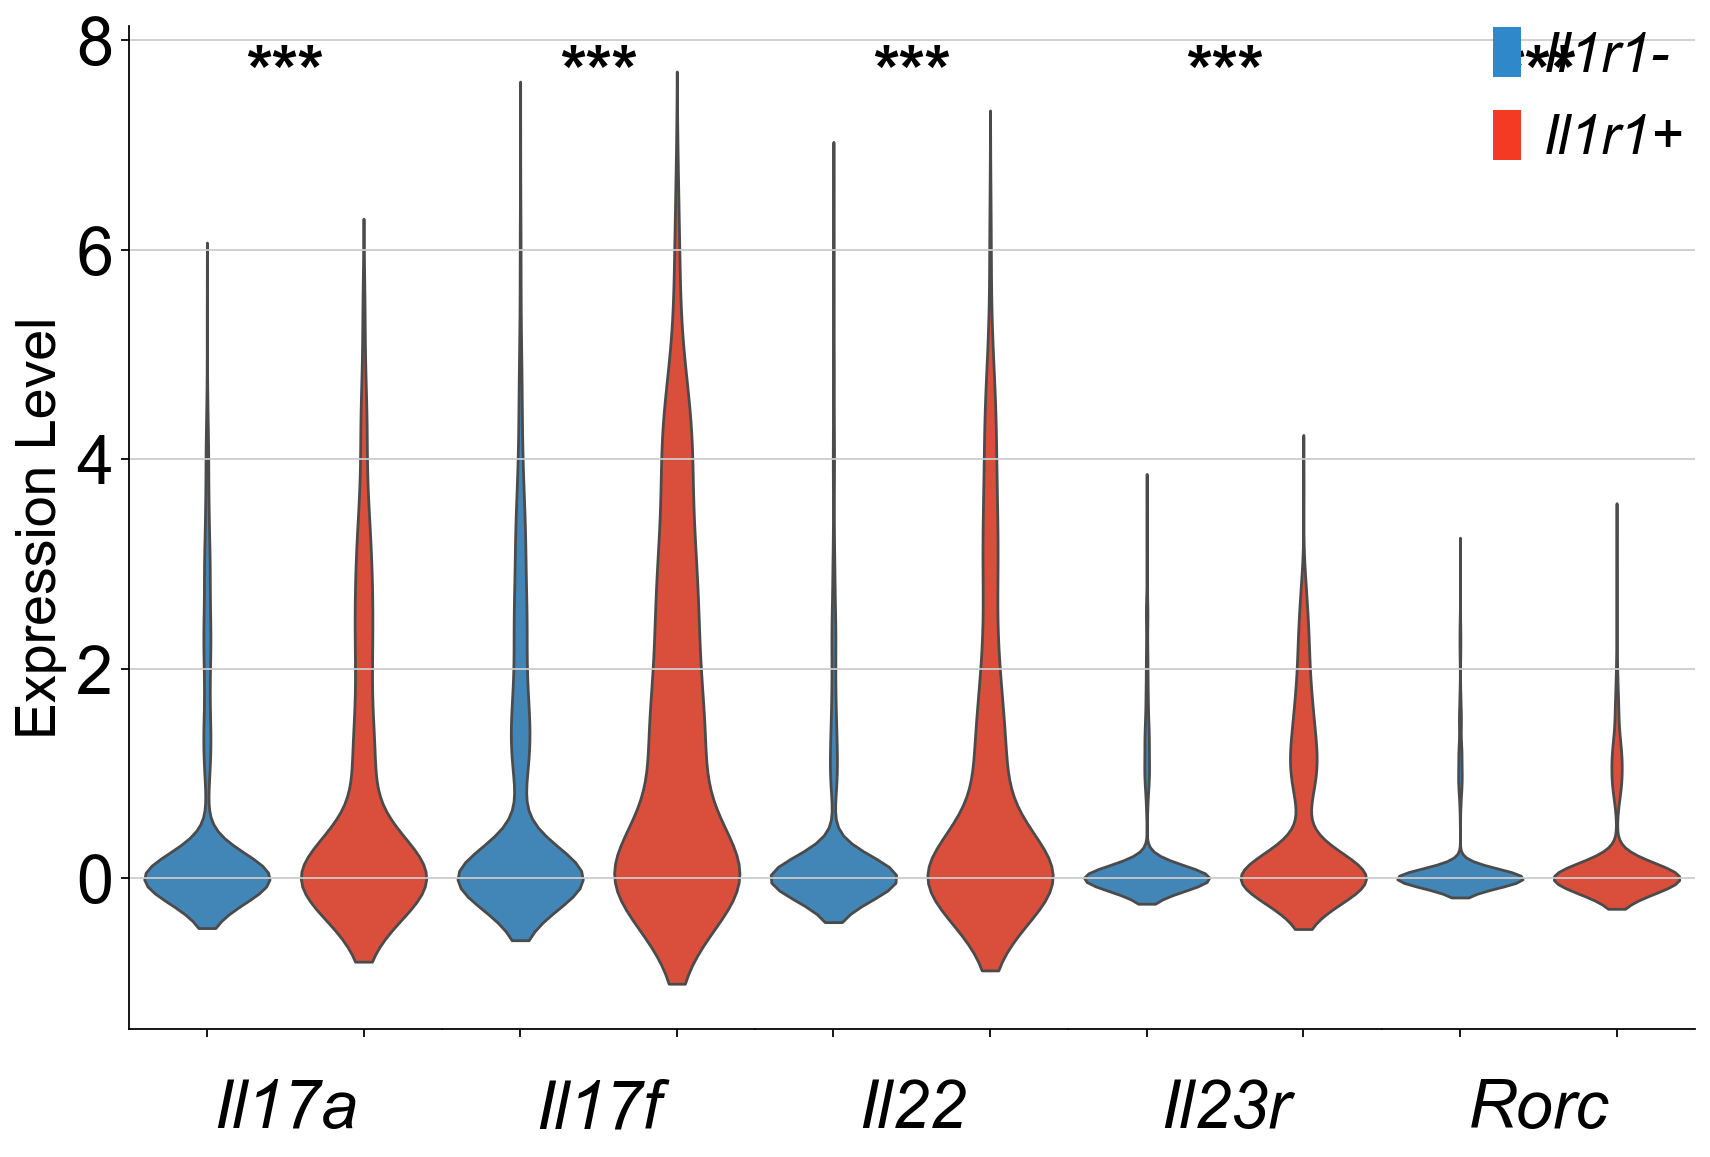

In [46]:
# Genes to plot
genes = ['Il17a', 'Il17f', 'Il22', 'Il23r', 'Rorc']

# Create subplots 
fig, axes = plt.subplots(1, 5, figsize=(10.5, 7), sharey=True)
fig.subplots_adjust(wspace=0) 

# Determine global y-axis limits
all_expression_data = []
for gene in genes:
    for status in ['Il1r1-', 'Il1r1+']:
        status_cells = th17_cells[th17_cells.obs['Il1r1_status'] == status]
        if gene in status_cells.var_names:
            expression = status_cells[:, gene].X.toarray().flatten()
            all_expression_data.extend(expression)

# Set global y-axis limits 
y_min = min(all_expression_data)
y_max = max(all_expression_data)
y_padding = (y_max - y_min) * 0.1
y_lim = [y_min - y_padding, y_max + y_padding]

for i, gene in enumerate(genes):
    ax = axes[i]
    
    plot_data = []
    for status in ['Il1r1-', 'Il1r1+']:
        status_cells = th17_cells[th17_cells.obs['Il1r1_status'] == status]
        if gene in status_cells.var_names:
            expression = status_cells[:, gene].X.toarray().flatten()
            for expr in expression:
                plot_data.append({
                    'Il1r1_status': status,
                    'Expression': expr
                })
    
    df_gene = pd.DataFrame(plot_data)
    
    sns.violinplot(data=df_gene, x='Il1r1_status', y='Expression',
                   order=['Il1r1-', 'Il1r1+'],
                   palette={'Il1r1-': '#2f88ca', 'Il1r1+': '#f43a22'},
                   ax=ax, width=0.8, inner=None)  
    
    il1r1_pos_data = df_gene[df_gene['Il1r1_status'] == 'Il1r1+']['Expression']
    il1r1_neg_data = df_gene[df_gene['Il1r1_status'] == 'Il1r1-']['Expression']
    statistic, p_value = stats.mannwhitneyu(il1r1_pos_data, il1r1_neg_data, alternative='two-sided')
    
    if p_value < 0.001:
        sig_text = '***'
    elif p_value < 0.01:
        sig_text = '**'
    elif p_value < 0.05:
        sig_text = '*'
    else:
        sig_text = 'ns'
    
    ax.text(0.5, y_max * 1.05, sig_text, ha='center', va='bottom', 
            fontsize=30, fontweight='bold')
    
    ax.set_xlabel('', fontsize=30)
    ax.set_ylabel('', fontsize=30)
    ax.tick_params(axis='x', labelsize=30)
    ax.tick_params(axis='y', labelsize=30)
    
    ax.set_xticklabels([])
    
    if i > 0:
        ax.spines['left'].set_visible(False)
        ax.tick_params(axis='y', left=False, labelleft=False)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.legend().set_visible(False)

axes[0].set_ylabel('Expression Level', fontsize=25)

for i, gene in enumerate(genes):
    axes[i].text(0.5, -0.05, gene, ha='center', va='top', 
                transform=axes[i].transAxes, fontstyle='italic', fontsize=30)

# Custom legend
legend_elements = [Patch(facecolor='#2f88ca', label='Il1r1-'),
                   Patch(facecolor='#f43a22', label='Il1r1+')]
legend = fig.legend(handles=legend_elements, loc='upper right', fontsize=25)
for text in legend.get_texts():
    text.set_fontstyle('italic')

plt.tight_layout(pad=0)
plt.savefig('th17_violin_plots_il1r1_status.svg', dpi=300, bbox_inches='tight')
plt.show()

In [47]:
pval_results = []

for gene in genes:
    plot_data = []

    for status in ['Il1r1-', 'Il1r1+']:
        status_cells = th17_cells[th17_cells.obs['Il1r1_status'] == status]

        if gene in status_cells.var_names:
            x = status_cells[:, gene].X
            expression = x.toarray().flatten() if hasattr(x, "toarray") else np.asarray(x).flatten()

            for expr in expression:
                plot_data.append({
                    'Il1r1_status': status,
                    'Expression': expr
                })

    df_gene = pd.DataFrame(plot_data)

    il1r1_pos_data = df_gene[df_gene['Il1r1_status'] == 'Il1r1+']['Expression']
    il1r1_neg_data = df_gene[df_gene['Il1r1_status'] == 'Il1r1-']['Expression']

    statistic, p_value = stats.mannwhitneyu(
        il1r1_pos_data,
        il1r1_neg_data,
        alternative='two-sided'
    )

    pval_results.append({
        'Gene': gene,
        'n_Il1r1_neg': len(il1r1_neg_data),
        'n_Il1r1_pos': len(il1r1_pos_data),
        'U_statistic': statistic,
        'p_value': p_value,
        'significance': (
            '***' if p_value < 0.001 else
            '**' if p_value < 0.01 else
            '*' if p_value < 0.05 else
            'ns'
        )
    })

pvals_df = pd.DataFrame(pval_results)

print(
    pvals_df.to_string(
        index=False,
        formatters={'p_value': '{:.3e}'.format}
    )
)

 Gene  n_Il1r1_neg  n_Il1r1_pos  U_statistic   p_value significance
Il17a         1832          388     400558.5 9.396e-08          ***
Il17f         1832          388     438840.0 6.006e-17          ***
 Il22         1832          388     435260.0 4.711e-23          ***
Il23r         1832          388     430364.0 6.819e-24          ***
 Rorc         1832          388     377304.0 3.879e-04          ***


### Pathogenicity score

Extended Data Figure 6c

Found 123 genes in Th17 cells
computing score 'Th17_Pathogenicity_Score'
    finished: added
    'Th17_Pathogenicity_Score', score of gene set (adata.obs).
    1179 total control genes are used. (0:00:00)


/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/3063319287.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=plot_data, x='sample', y='score',


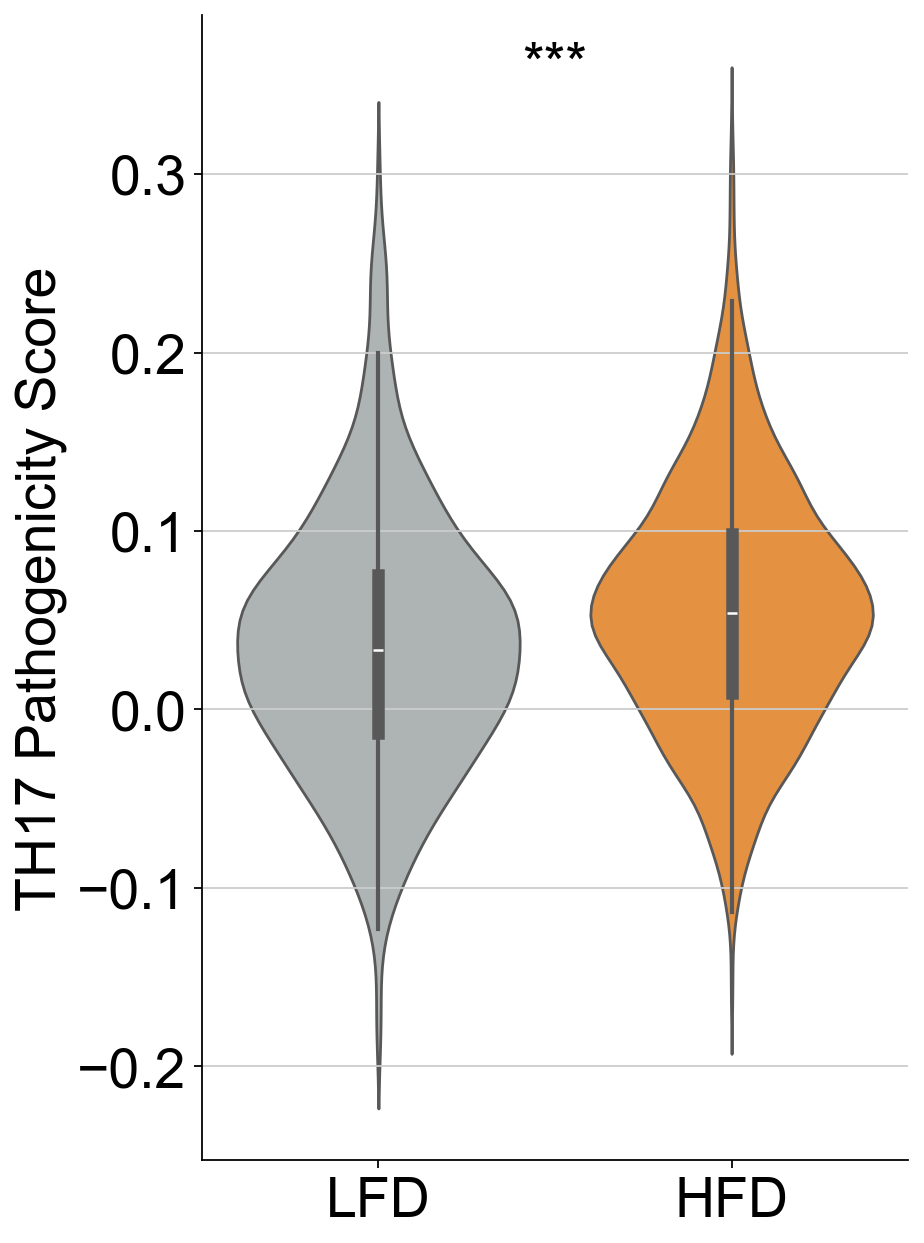

p-value: 3.6106e-08


In [ ]:
# Get genes that are found in the Th17 cluster
th17_genes = th17_cells.var_names.tolist()
combined_genes_found = [gene for gene in combined_genes if gene in th17_genes]

# Check if there are enough genes
if len(combined_genes_found) < 2:
    print("Not enough combined genes found in the object")
else:
    print(f"Found {len(combined_genes_found)} genes in Th17 cells")
    
    # Calculate Th17 pathogenicity score
    sc.tl.score_genes(th17_cells, combined_genes_found, score_name='Th17_Pathogenicity_Score')
    
    # Prepare data for plotting
    plot_data = pd.DataFrame({
        'sample': th17_cells.obs['sample'].values,
        'score': th17_cells.obs['Th17_Pathogenicity_Score'].values
    })
    
    # Perform statistical test
    hfd_scores = plot_data[plot_data['sample'] == 'HFD']['score']
    lfd_scores = plot_data[plot_data['sample'] == 'LFD']['score']
    _, p_val = mannwhitneyu(hfd_scores, lfd_scores, alternative='two-sided')
    
    # Determine significance
    if p_val < 0.001:
        significance = '***'
    elif p_val < 0.01:
        significance = '**'
    elif p_val < 0.05:
        significance = '*'
    else:
        significance = 'ns'
    
    # Create violin plot
    fig, ax = plt.subplots(figsize=(6, 8))
    
    sns.violinplot(data=plot_data, x='sample', y='score', 
                   order=['LFD', 'HFD'],
                   palette={'LFD': '#acb5b4', 'HFD': '#ff9127'}, ax=ax)
    
    ax.set_xlabel('', fontsize=25)
    ax.set_ylabel('TH17 Pathogenicity Score', fontsize=25)
    ax.tick_params(axis='both', labelsize=25)
    
    sns.despine()
    
    # Add significance annotation
    y_max = plot_data['score'].max()
    ax.text(0.5, y_max * 1.05, significance, 
            ha='center', va='bottom', fontsize=25, color='black')
    
    plt.tight_layout()
    plt.savefig('th17_pathogenicity_violin_plot.svg', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"p-value: {p_val:.4e}")

In [49]:
plot_data_path = pd.DataFrame({
    'Il1r1_status': th17_cells.obs['Il1r1_status'].values,
    'score': th17_cells.obs['Th17_Pathogenicity_Score'].values
})

### Pathogenicity Score Il1r1+ vs. Il1r1- cells

Extended Data Figure 6g

/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/85274382.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=plot_data_path, x='Il1r1_status', y='score',
/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_85006/85274382.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Il1r1-', 'Il1r1+'], fontstyle='italic')


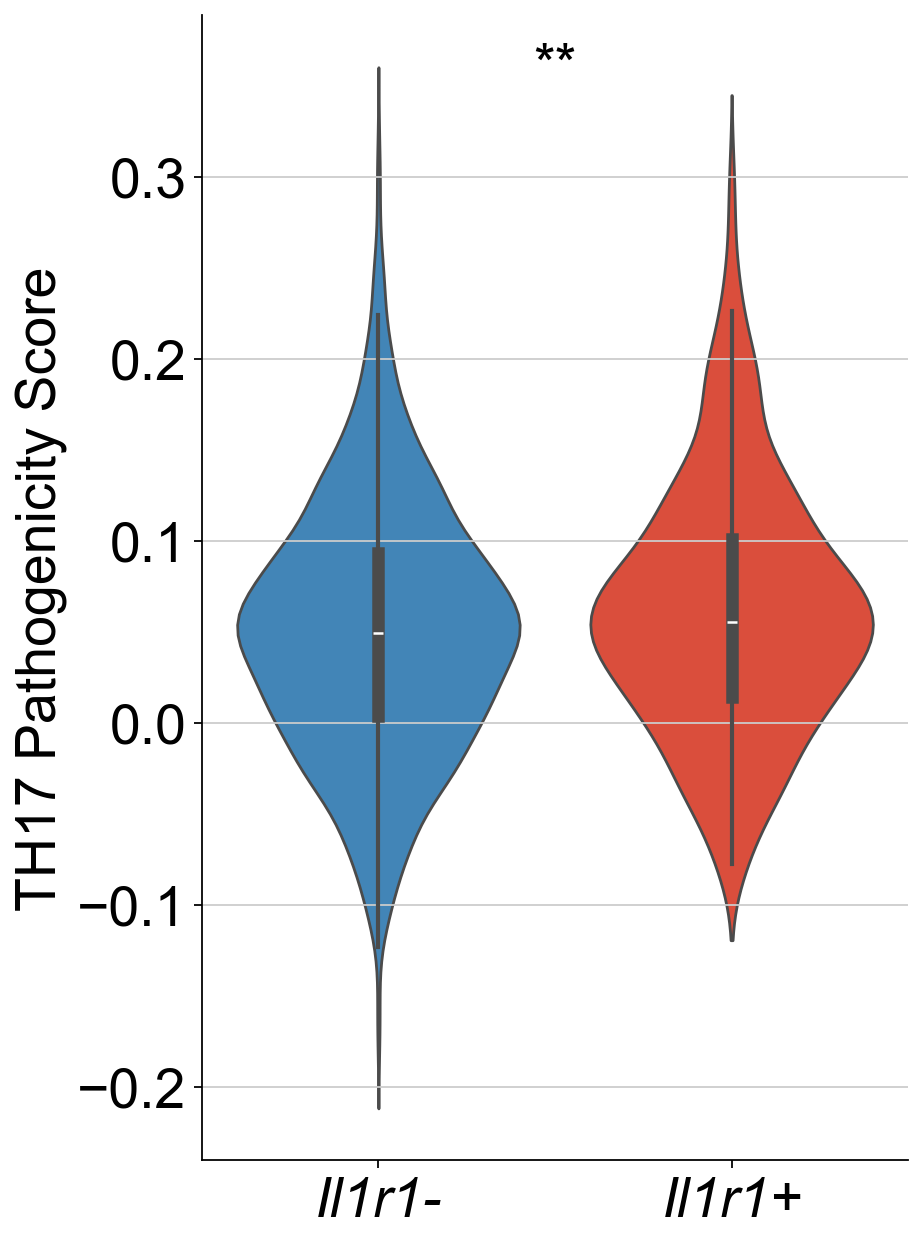

Pathogenicity score p-value: 8.8670e-03


In [50]:

il1r1_expression = th17_cells[:, 'Il1r1'].X.toarray().flatten()
th17_cells.obs['Il1r1_status'] = ['Il1r1+' if expr > 0 else 'Il1r1-' for expr in il1r1_expression]

# Define colors
il1r1_colors = {'Il1r1-': '#2f88ca', 'Il1r1+': '#f43a22'}

# 1. Pathogenicity score violin plot
plot_data_path = pd.DataFrame({
    'Il1r1_status': th17_cells.obs['Il1r1_status'].values,
    'score': th17_cells.obs['Th17_Pathogenicity_Score'].values
})

il1r1_pos = plot_data_path[plot_data_path['Il1r1_status'] == 'Il1r1+']['score']
il1r1_neg = plot_data_path[plot_data_path['Il1r1_status'] == 'Il1r1-']['score']
_, p_val = mannwhitneyu(il1r1_pos, il1r1_neg, alternative='two-sided')

if p_val < 0.001:
    significance = '***'
elif p_val < 0.01:
    significance = '**'
elif p_val < 0.05:
    significance = '*'
else:
    significance = 'ns'

fig, ax = plt.subplots(figsize=(6, 8))

sns.violinplot(data=plot_data_path, x='Il1r1_status', y='score',
                order=['Il1r1-', 'Il1r1+'],
                palette=il1r1_colors, ax=ax)

ax.set_xlabel('', fontsize=25)
ax.set_ylabel('TH17 Pathogenicity Score', fontsize=25)
ax.tick_params(axis='both', labelsize=25)

sns.despine()

y_max = plot_data_path['score'].max()
ax.text(0.5, y_max * 1.05, significance,
        ha='center', va='bottom', fontsize=25, color='black')
ax.set_xticklabels(['Il1r1-', 'Il1r1+'], fontstyle='italic')

plt.tight_layout()
plt.savefig('th17_pathogenicity_il1r1_violin_plot.svg', dpi=300, bbox_inches='tight')
plt.show()

print(f"Pathogenicity score p-value: {p_val:.4e}")
